# **PROJECT NAME: NETFLIX MOVIES AND TV SHOW CLUSTERING**

Project Type: ML Unsupervised

Contribution:Individual

Name: Akshata Rajesh Ram

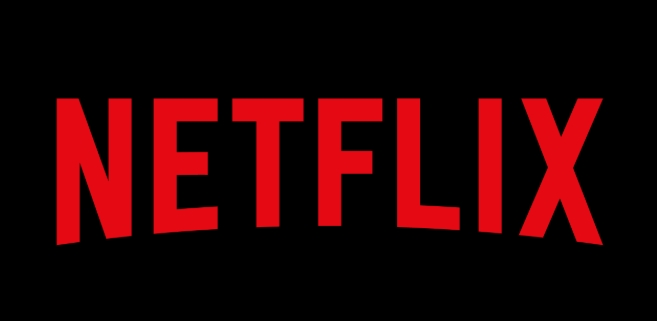

# **PROJECT SUMMARY**

[link text](https://)
This project aims to analyze the Netflix Dataset of movies and TV shows until 2019, obtained from the third-party search engine Flixable. The primary objective is to group the content into relevant clusters using NLP techniques to enhance the user experience through a recommendation system. This system will help mitigate subscriber churn for Netflix, which currently boasts over 220 million subscribers.

Moreover, this project seeks to uncover valuable insights and trends in the streaming entertainment industry by analyzing the dataset.

Project Overview The project was carried out in the following step-by-step process:

Handling Null Values: Null values in the dataset were addressed to ensure data integrity and accuracy.

Managing Nested Columns: Columns containing nested data, such as director, cast, listed_in, and country, were processed to enable better visualization and analysis.

Binning Ratings: The rating attribute was binned into categories such as adult, children's, family-friendly, and not rated to facilitate analysis and recommendation.

Exploratory Data Analysis (EDA): EDA techniques were employed to gain insights and understand patterns and trends in the dataset, with the goal of preventing subscriber churn.

Creating Clusters: Clustering techniques were applied to group the content based on attributes like director, cast, country, genre, rating, and description. These attributes were tokenized, preprocessed, and vectorized using the TF-IDF vectorizer.

Dimensionality Reduction: The dimensionality of the dataset was reduced using Principal Component Analysis (PCA) to improve performance and eliminate noise.

Clustering Algorithms: Both K-Means Clustering and Agglomerative Hierarchical Clustering algorithms were utilized to create clusters. The optimal number of clusters was determined (4 for K-Means and 2 for hierarchical clustering) using various evaluation methods.

Content-Based Recommender System: A content-based recommender system was developed using the cosine similarity matrix to provide personalized recommendations to users. The aim was to reduce subscriber churn by offering relevant and engaging content.

The comprehensive analysis and recommendation system developed in this project are expected to enhance user satisfaction and ultimately improve subscriber retention rates for Netflix.

**PROBLEM STATEMENT**

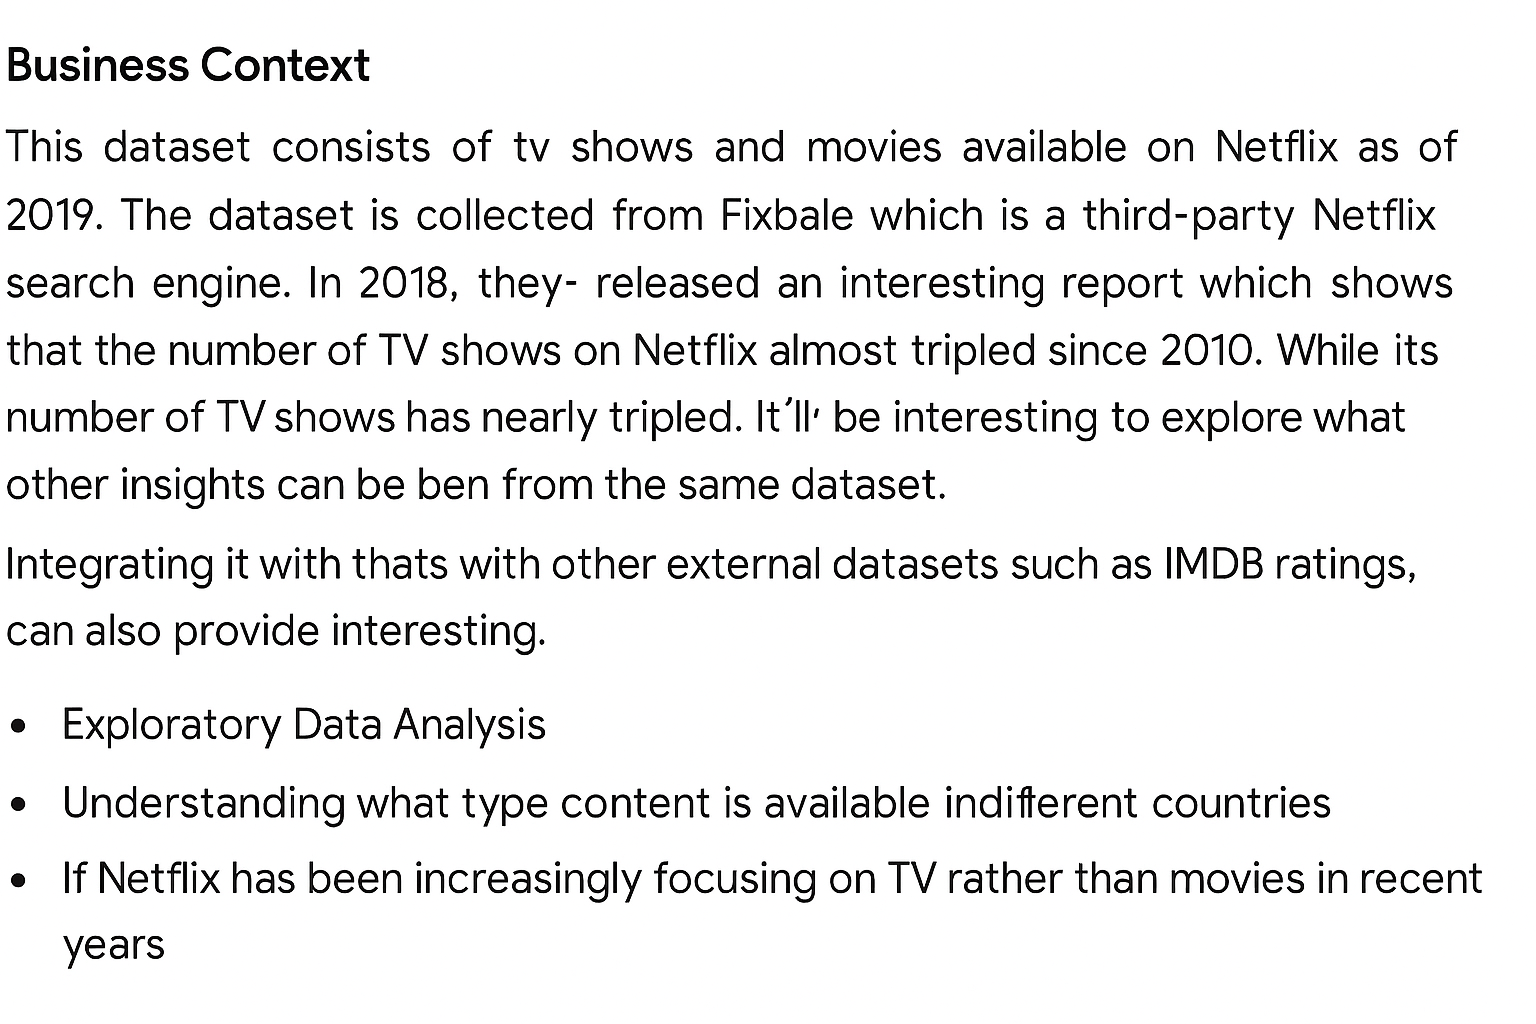

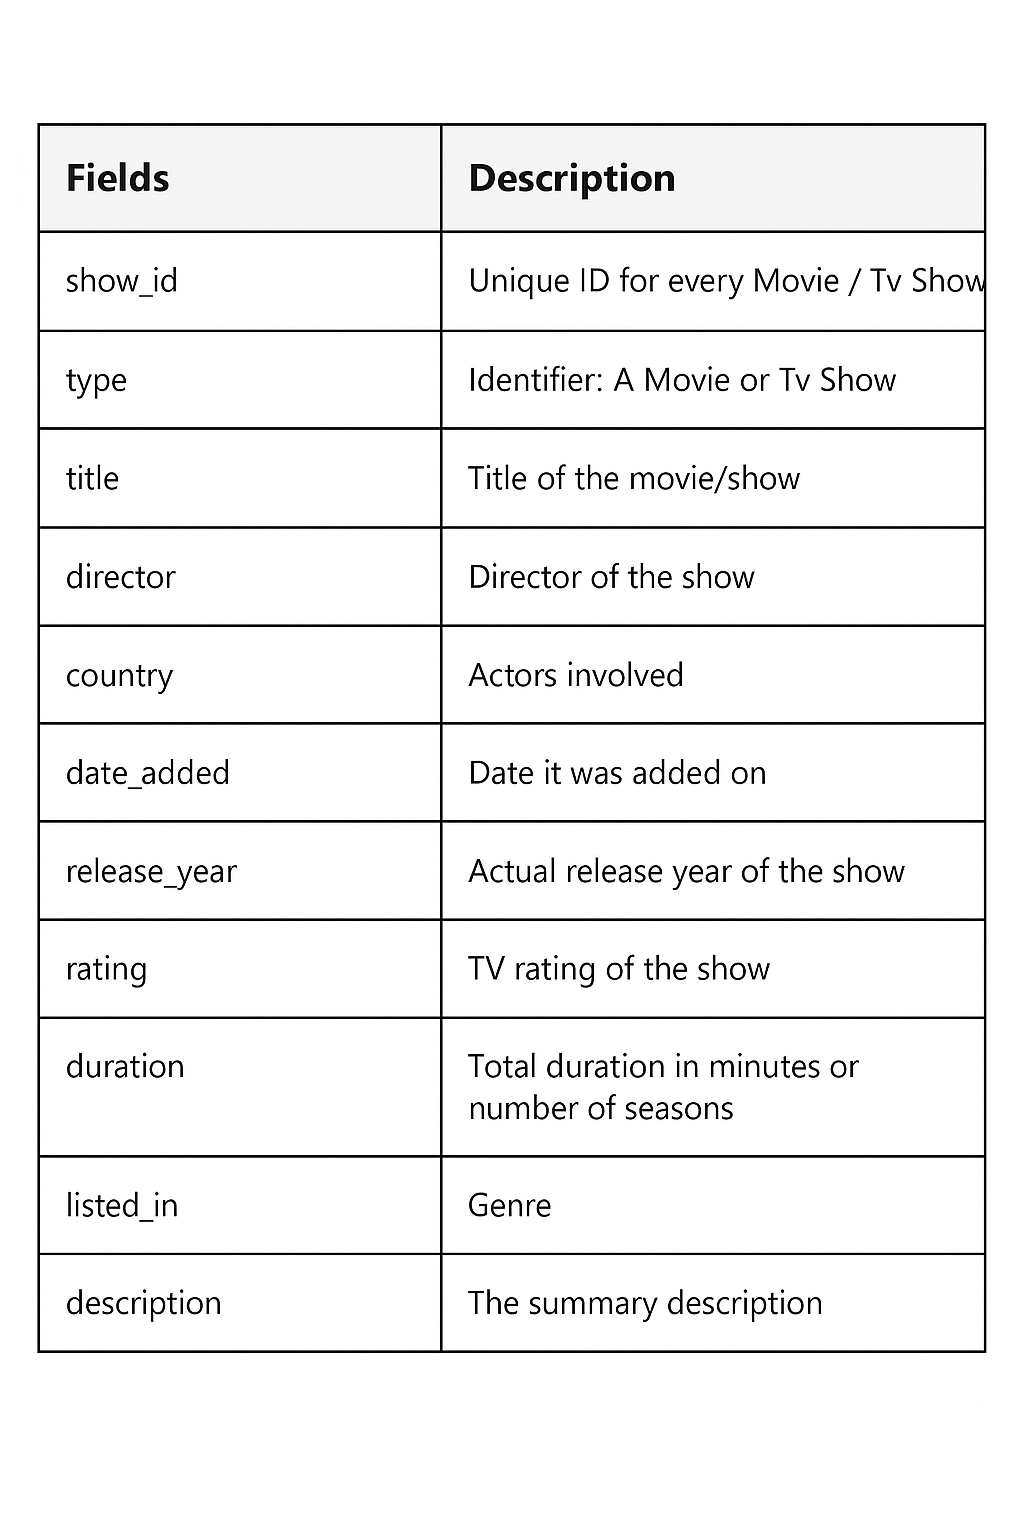

**Github Link**

https://github.com/AkshataRajeshRam

# **Let's Begin!!**

# **1. Know Your Data**

# Import Libraries

In [ ]:
#Import Libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import missingno as msno

import datetime as dt

from sklearn import preprocessing
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import MinMaxScaler, StandardScaler

from sklearn.decomposition import PCA

from sklearn.cluster import KMeans, SpectralClustering, AgglomerativeClustering
from sklearn.metrics import silhouette_samples, silhouette_score
import scipy.cluster.hierarchy as sch

import warnings
warnings.filterwarnings('ignore')






# **Dataset Loading**

In [ ]:
#Load Dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#reading the dataset
import pandas as pd

url = 'https://drive.google.com/uc?id=1xJGllnE12mAggLuRo8b0oNSshUlG8GvF'
df = pd.read_csv(url)
df.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


# Dataset First View

In [ ]:
#Dataset First Look
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


# Dataset Rows and Coloumns Count

In [ ]:
#Dataset Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   object
 10  listed_in     7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(1), object(11)
memory usage: 730.2+ KB


# Duplicate Values

In [ ]:
#Dataset Duplicate Value Count
len(df[df.duplicated()])

0

# Missing Values/Null Values

In [ ]:
#Missing Values/ Null Values Count
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2389
cast,718
country,507
date_added,10
release_year,0
rating,7
duration,0


In [ ]:
#Total null values present in the data
df.isnull().sum().sum()

np.int64(3631)

<Axes: >

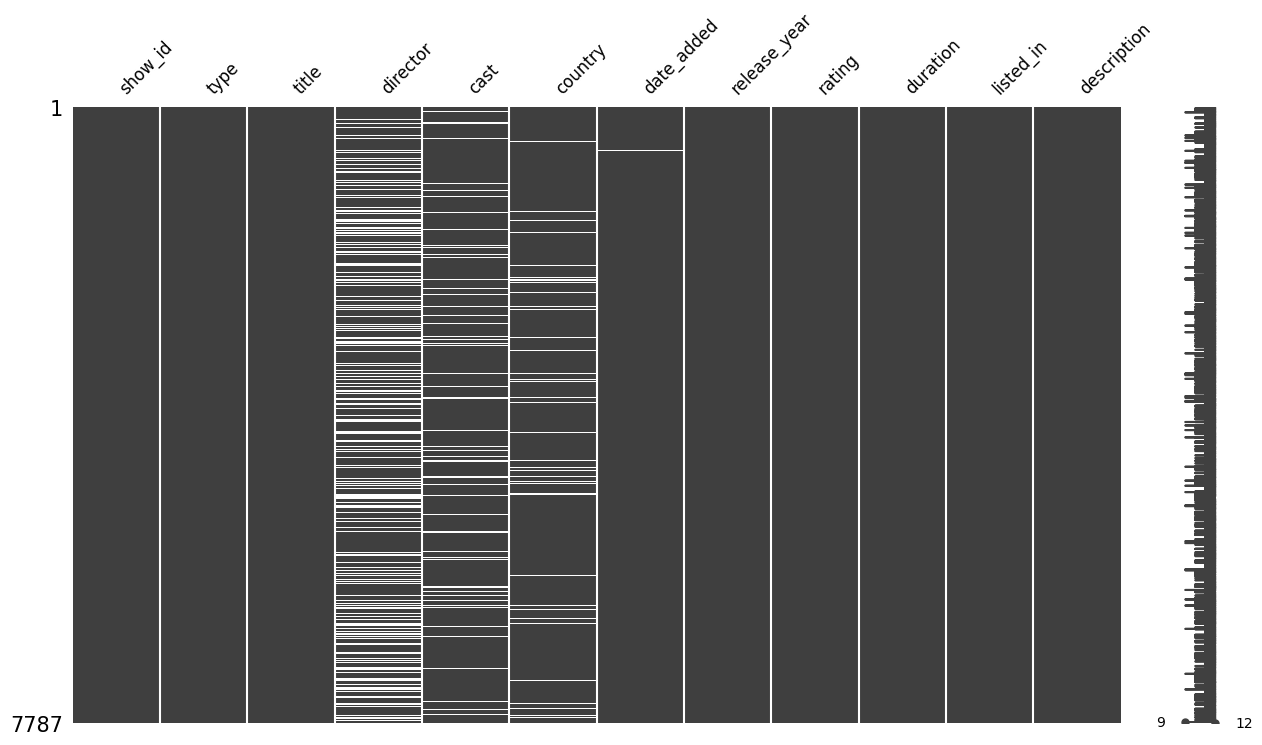

In [ ]:
#Visualizing the missing values
msno.matrix(df, figsize = (15,8), fontsize=(12))

This dataset contains 7787 observations with 12 features. It has some null values present in director, cast, country, date_added and rating.

# **Understanding Variables**

In [ ]:
#Dataset Coloumns
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [ ]:
#Dataset Describe
df.describe()

,release_year
count,7787.000000
mean,2013.932580
std,8.757395
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2018.000000
max,2021.000000


In [ ]:
#Description of all the features
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,7787,7787,s7787,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,7787,2,Movie,5377,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,7787,7787,ZZ TOP: THAT LITTLE OL' BAND FROM TEXAS,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,5398,4049,"Raúl Campos, Jan Suter",18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7069,6831,David Attenborough,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7280,681,United States,2555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,7777,1565,"January 1, 2020",118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,7787.0,NaN,NaN,NaN,2013.93258,8.757395,1925.0,2013.0,2017.0,2018.0,2021.0
rating,7780,14,TV-MA,2863,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,7787,216,1 Season,1608,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Variables Description

**show_id** :Unique id for every movie/TV shows

**type** : Identifier-A movie or TV show

**title** : Title of the movie/show

**director** : Director of the show

**cast** : Actors involved in the show

**Country** : Country of production

**date_added** : Date is what added on netflix

**release_year** : Actual release year of the show

**rating** : TV rating of the show

**duration** : Total duration in minutes or number of seasons

**listed_in** : Genre

**Description** : The summary description

# Check Unique Values for each variable

In [ ]:
#Check Unique Values for each variable
variables_data = df.columns.to_list()
for item in variables_data:
  print('The Unique Values of', item, 'are:', df[item].unique())


The Unique Values of show_id are: ['s1' 's2' 's3' ... 's7785' 's7786' 's7787']
The Unique Values of type are: ['TV Show' 'Movie']
The Unique Values of title are: ['3%' '7:19' '23:59' ... 'Zulu Man in Japan' "Zumbo's Just Desserts"
 "ZZ TOP: THAT LITTLE OL' BAND FROM TEXAS"]
The Unique Values of director are: [nan 'Jorge Michel Grau' 'Gilbert Chan' ... 'Josef Fares' 'Mozez Singh'
 'Sam Dunn']
The Unique Values of cast are: ['João Miguel, Bianca Comparato, Michel Gomes, Rodolfo Valente, Vaneza Oliveira, Rafael Lozano, Viviane Porto, Mel Fronckowiak, Sergio Mamberti, Zezé Motta, Celso Frateschi'
 'Demián Bichir, Héctor Bonilla, Oscar Serrano, Azalia Ortiz, Octavio Michel, Carmen Beato'
 'Tedd Chan, Stella Chung, Henley Hii, Lawrence Koh, Tommy Kuan, Josh Lai, Mark Lee, Susan Leong, Benjamin Lim'
 ...
 'Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanana, Manish Chaudhary, Meghna Malik, Malkeet Rauni, Anita Shabdish, Chittaranjan Tripathy'
 'Nasty C' 'Adriano Zumbo, Rachel Khoo']
The Unique Va

# ***Data Wrangling***

In [ ]:
#copy of the data
df = df.copy()

In [ ]:
#handling null values
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2389
cast,718
country,507
date_added,10
release_year,0
rating,7
duration,0


In [ ]:
#filling the null values of director and cast
df.fillna({'director':'name absent','cast':'name missing'}, inplace=True)

#filling the null values of rating and country with their mode
df['country'].fillna(df ['country'].mode()[0],inplace=True)
df['rating'].fillna(df['rating'].mode()[0], inplace=True)

#Droping the observation with null values present in date added
df=df[df['date_added'].notna()]

In [ ]:
#Checking the null value counts again
df.isnull().sum().sum()

np.int64(0)

In [ ]:
#Checking the data type of data
df.date_added.dtype

dtype('O')

In [ ]:
#Remove Leading/trailing spaces
df['date_added'] = df['date_added'].str.strip()

#Converting date_added column to date time and extracting the day, month and year from the column extracting day, month and year
df['date_added']=pd.to_datetime(df['date_added'], errors='coerce')

#Extract day, month and year
df['added_day'] = df['date_added'].dt.day

df['added_month'] = df['date_added'].dt.month

df['added_year'] = df['date_added'].dt.year

In [ ]:
#Columns
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description',
       'added_day', 'added_month', 'added_year'],
      dtype='object')

# Understanding the rating value

In [ ]:
#rating value counts
df['rating'].value_counts()

,count
rating,
TV-MA,2868
TV-14,1928
TV-PG,804
R,665
PG-13,386
TV-Y,279
TV-Y7,270
PG,247
TV-G,194


In [ ]:
#Converting rating into understandable format
rename_rating = {
    'TV-PG' : 'Older Kids',
    'TV-MA': 'Adults',
    'TV-Y7-FV': 'Kids',
    'TV-Y7':'Kids',
    'TV-14': 'Teens',
    'R':'Adults',
    'TV-Y':'Kids',
    'NR':'Adults',
    'PG-13':'Teens',
    'TV-G':'Kids',
    'PG':'Older Kids',
    'G':'Kids',
    'UR':'Adults',
    'NC-17':'Adults'
}
df['rating']=df['rating'].replace(to_replace = rename_rating)
df['rating'].unique()

array(['Adults', 'Teens', 'Older Kids', 'Kids'], dtype=object)

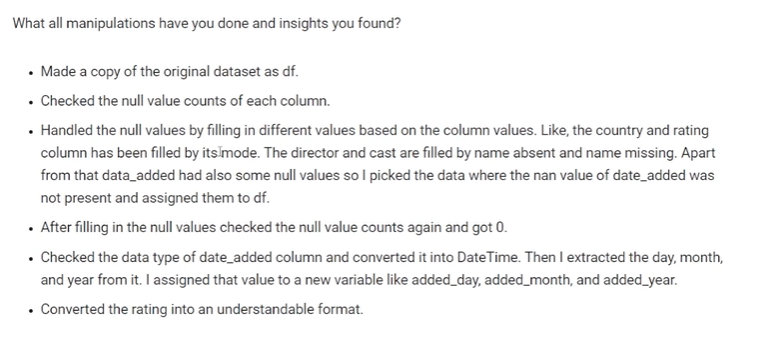

# **Data Visualization, Storytelling & Experimenting with charts: Understand the relationships between variables**

# **Shows type counts**

<Axes: xlabel='type', ylabel='count'>

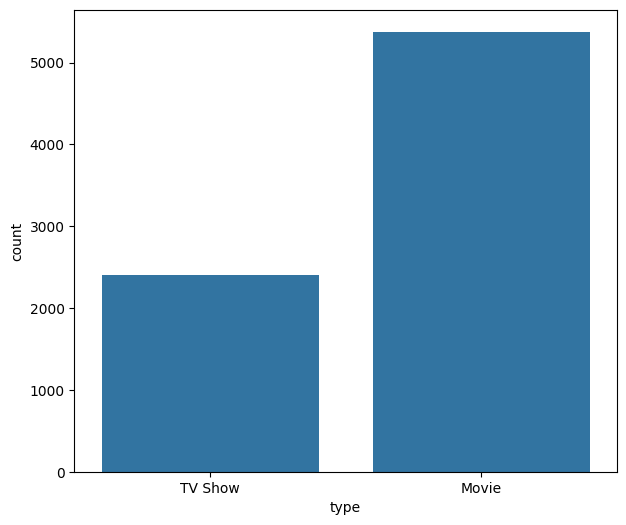

In [ ]:
from matplotlib import figure
#type counts
plt.figure(figsize=(7,6))
sns.countplot(x='type',data=df)

I picked a count plot here to see the total counts of each show.

We can clearly see in the count plot here that most of the content added is movies which are approximately 5000.
Nearly 2500 contents are TV Shows.

**Top ten countries based on total production**

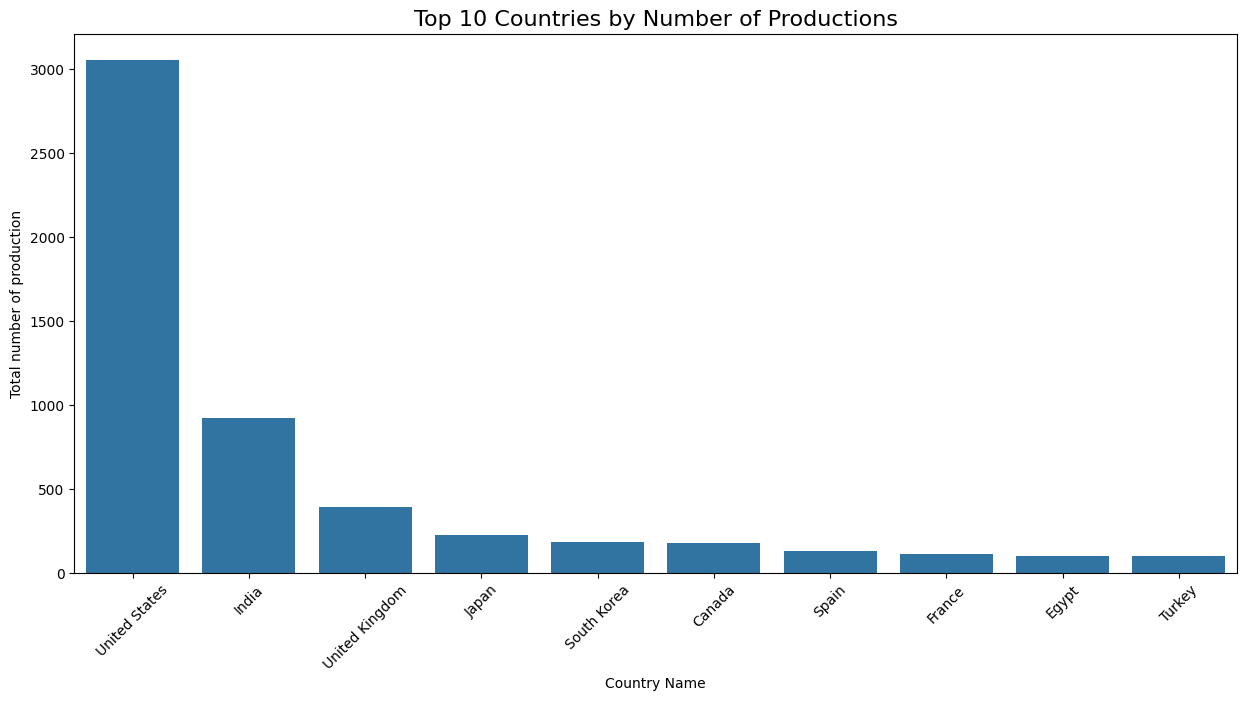

In [ ]:
#top ten countries based on number of tv shows and movies production
top_countries = df['country'].value_counts().head(10).reset_index()
top_countries.columns = ['Country Name', 'Total number of production']

plt.figure(figsize = (15,7))
sns.barplot(data = top_countries, x = 'Country Name', y= 'Total number of production')
plt.title('Top 10 Countries by Number of Productions', fontsize=16)
plt.xticks(rotation=45)
plt.show()

I wanted to see the top ten countries based on the total production so, I picked a barplot here. Barplot is very useful to see the data through bars with its its values.

According to the graph a huge number of contents are produced in the United States followed by India, UK and Japan. Whereas Spain, France, Egypt and Turkey have a very less number of production.

Total number of contents wrt added_year, added_month, added_day, release_year, rating, type

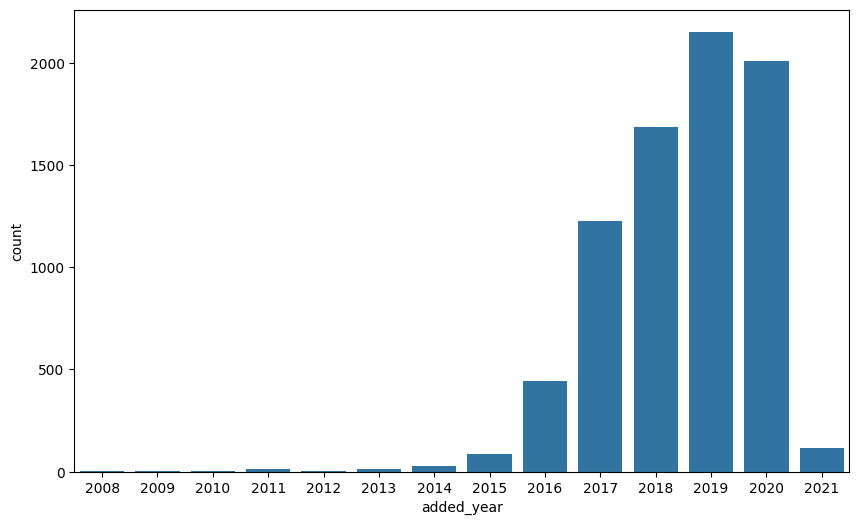

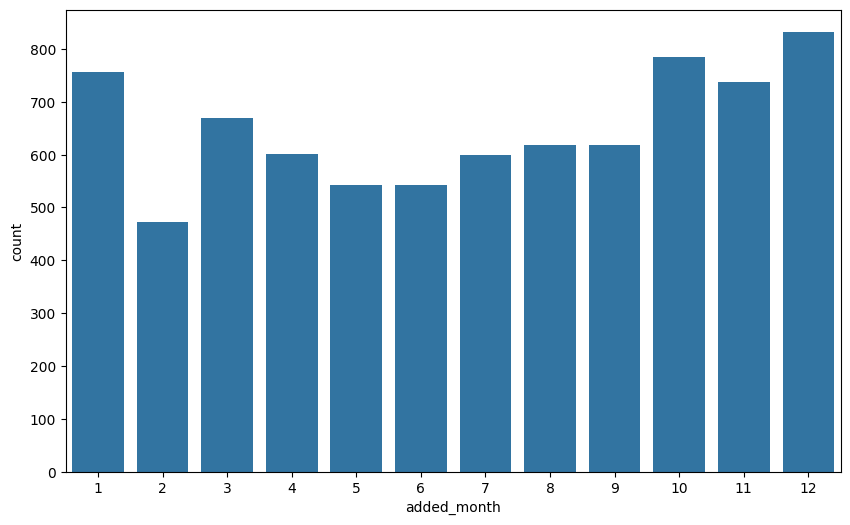

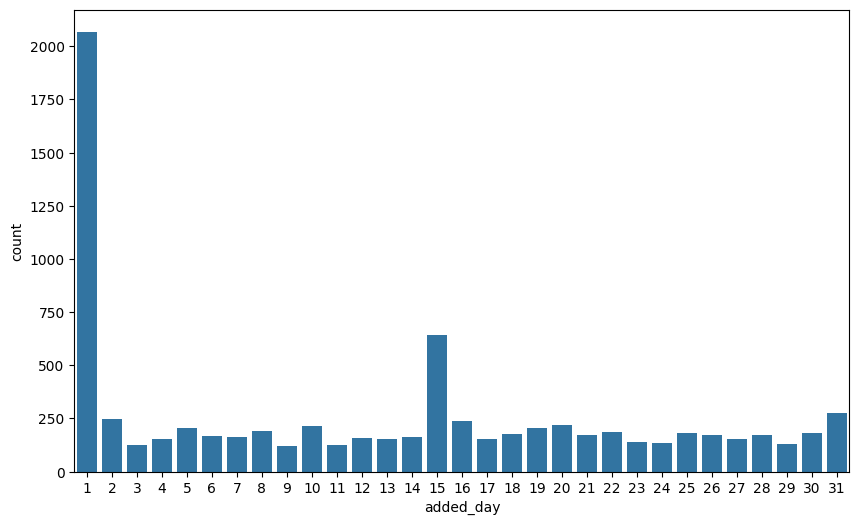

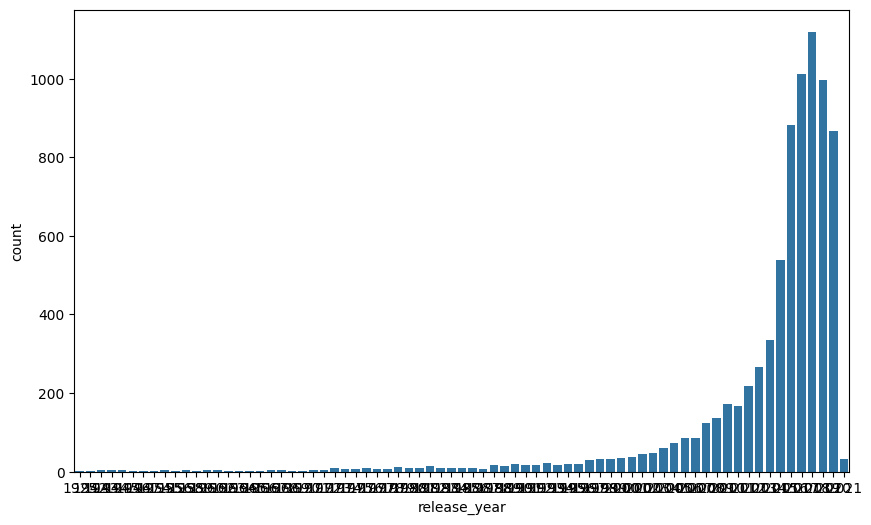

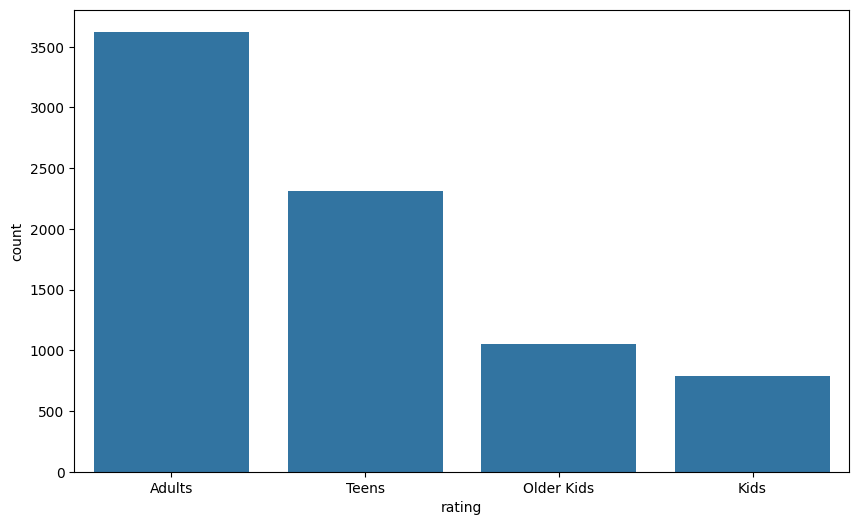

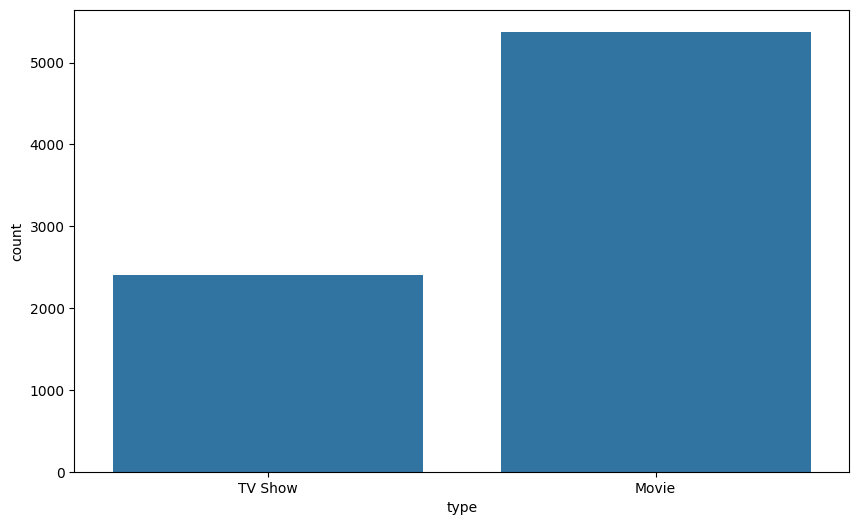

In [ ]:
#Visualizing
var = ['added_year', 'added_month', 'added_day', 'release_year', 'rating','type']

#years with total contents added
for col in var:
  plt.figure(figsize = (10,6))
  sns.countplot(x = col, data = df)
  plt.show()



*   **added_year** : Most of the content on Netflix is added in 2018,2019 and 2020. In which 2019 the maximum number of contents are added. This was the time when Netflix became prevalent among people. Very few contents are added in 2021 because of the pandemic.


*  ** added_month** : Most of the content on Netflix is added in the month of October, November, December and January. In which most numbers of the contents are added in the month of December. It is evident that in December, people usually have vacations that are the reason.



*   **added_day** : Maximum contents are added on the first day of the month followed by the 15th day of the month.

*   release_year : The number of contents released per year was increasing constantly but it got decreased in 2021, the reason was none other than the coronavirus pandemic in which everyone was following the restrictions to curb this virus from spreading.



*  **rating**: Maximum contents of Netflix are only for adults followed by teens. Very few contents are available for kids on Netflix.
*   **type**: Most of the content on Netflix is movies which are approximately 5000. The number of TV shows is around 2500 on this platform.







**Directors**

In [ ]:
#count of unique director
df['director'].nunique()

4050

In [ ]:
#top directors
df['director'].value_counts()

,count
director,
name absent,2379
"Raúl Campos, Jan Suter",18
Marcus Raboy,16
Jay Karas,14
Cathy Garcia-Molina,13
...,...
Jonathan Helpert,1
Greg Kohs,1
Jacob Schwab,1


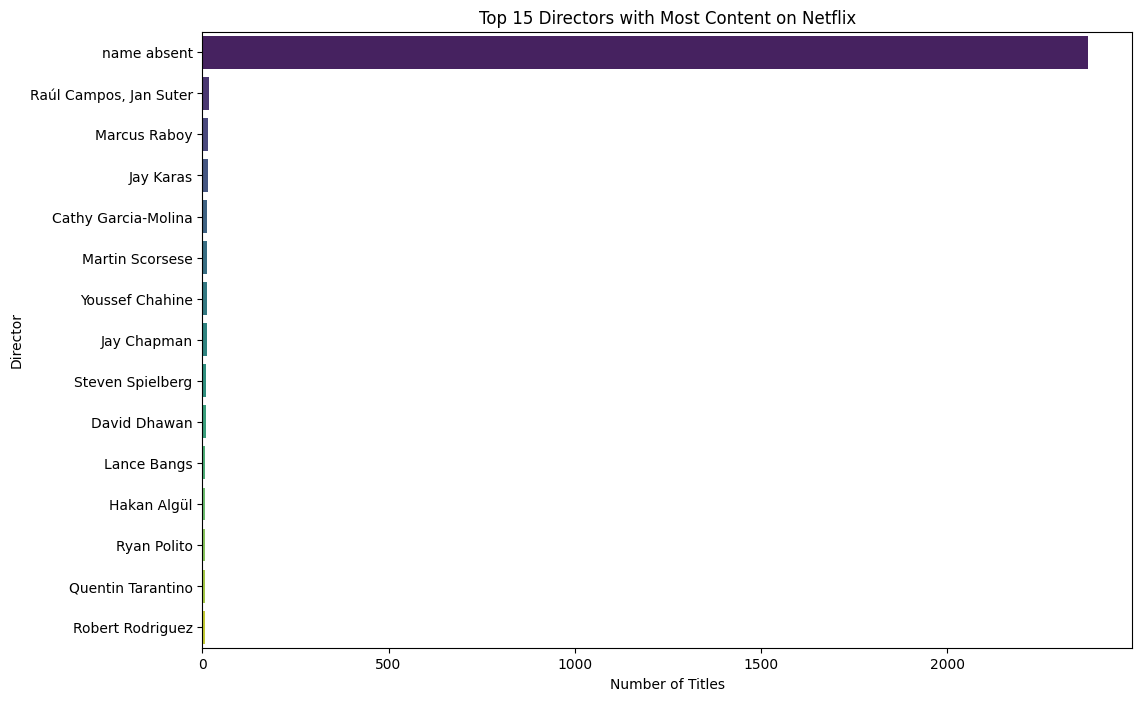

In [ ]:
#Visualization
plt.figure(figsize=(12,8))
top_directors=df['director'].value_counts().head(15)

sns.barplot(
    y=top_directors.index,
    x=top_directors.values,
    palette="viridis"
)

plt.title('Top 15 Directors with Most Content on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Director')
plt.show()

Raul Campos, Jan Suter, Marcus Raboy, Jay Karas, Cathy Garcia-Molina, etc are the top directors. It would have been easier to get more insights if some of the values in the director column were not null.

### **Titles**

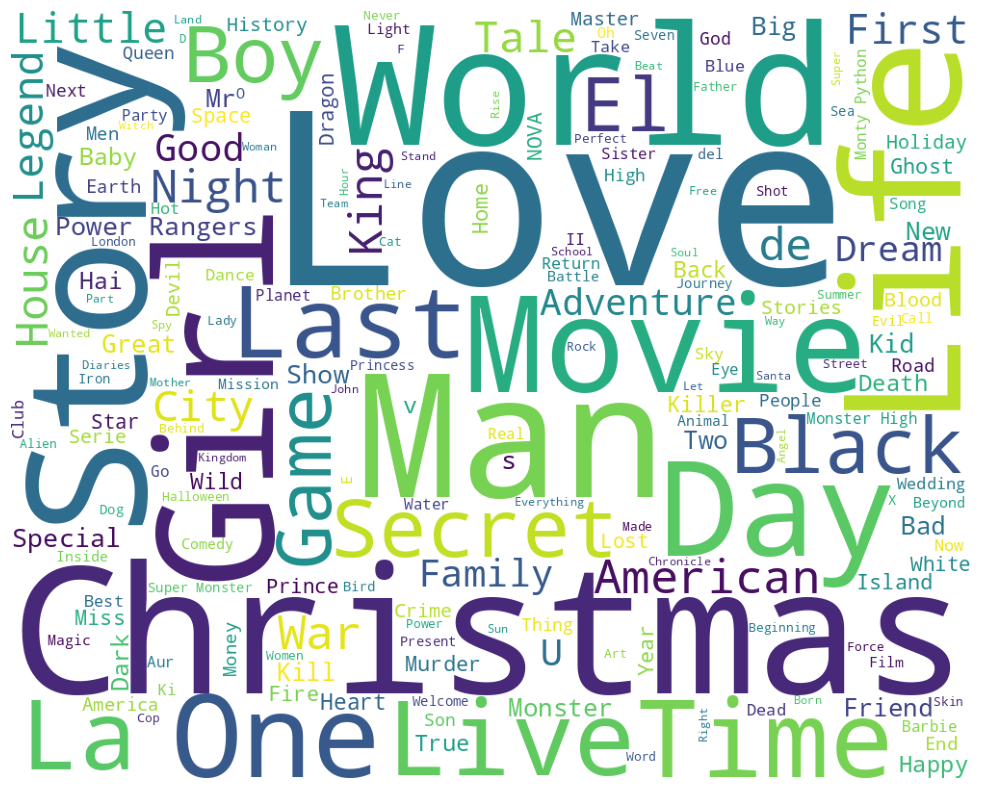

In [ ]:
#most frequent words used in titles
#Importing wordcloud
from wordcloud import WordCloud, STOPWORDS

#Most occured word in title
plt.subplots(figsize=(20,10))
stopwords= set(STOPWORDS)
text= " ".join(df.title)
wordcloud = WordCloud(stopwords = stopwords, background_color='white', width=1000, height=800).generate(text)
plt.imshow(wordcloud)
plt.axis('off')
plt.show()


Christmas, love, world, story, life, girl etc are the most frequent words used in the title of the contents.

# **Genres**

In [ ]:
#Value counts
df['listed_in'].value_counts()

,count
listed_in,
Documentaries,334
Stand-Up Comedy,321
"Dramas, International Movies",320
"Comedies, Dramas, International Movies",243
"Dramas, Independent Movies, International Movies",215
...,...
Sports Movies,1
"Crime TV Shows, TV Horror, TV Mysteries",1
"Children & Family Movies, Classic Movies, Dramas",1


<Axes: xlabel='count', ylabel='listed_in'>

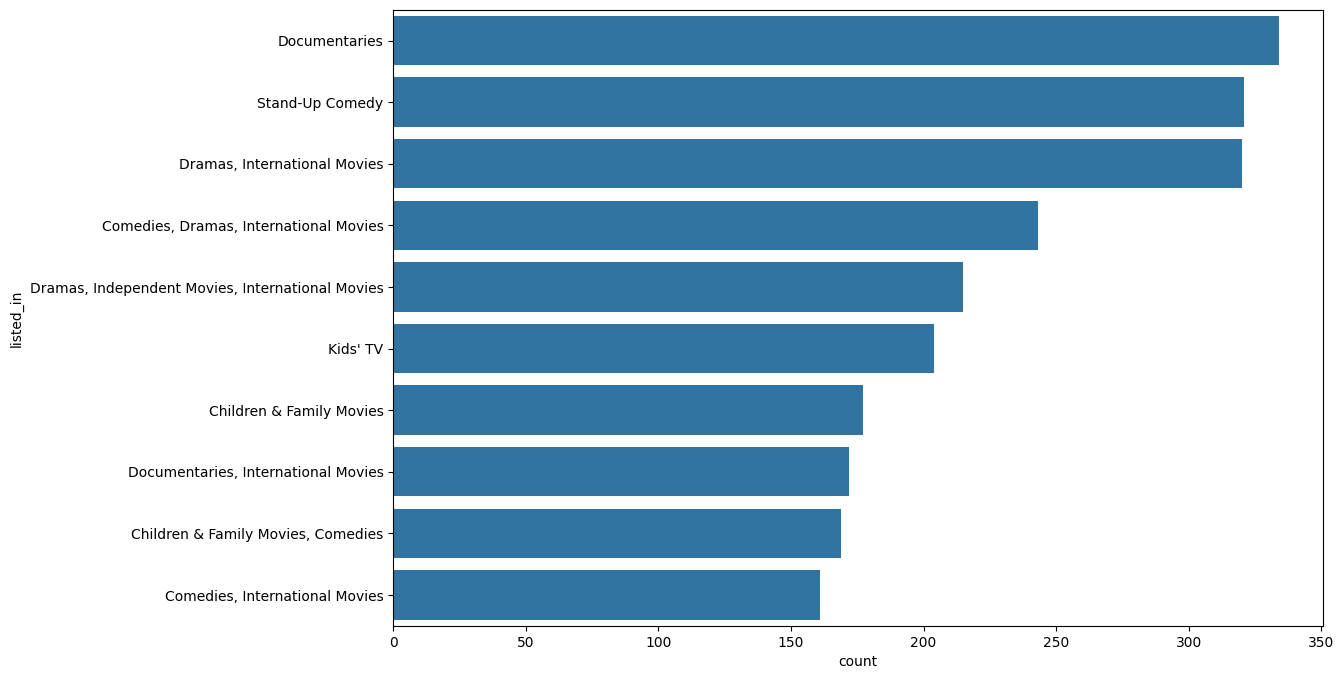

In [ ]:
#Visualization of top ten genres
plt.figure(figsize=(12,8))
sns.countplot(y=df['listed_in'], data=df, order = df['listed_in'].value_counts().index[:10])

**Top 15 genres**

In [ ]:
#Seperating the genres from every content and assigning them to a new genres list
genres= df['listed_in']
genre_list=[]
for i in genres:
  i=i.split(",")
  for j in i:
    genre_list.append(j)

In [ ]:
#converting genre list into dataframe
gen_df = pd.DataFrame(genre_list)
gen_df.rename(columns={0:'genres'},inplace= True)
gen_df.value_counts().head(15)

,count
genres,
International Movies,2323
Dramas,1384
Comedies,1074
Documentaries,751
Dramas,722
Action & Adventure,721
International TV Shows,689
Independent Movies,653
TV Dramas,641


<Axes: xlabel='count', ylabel='genres'>

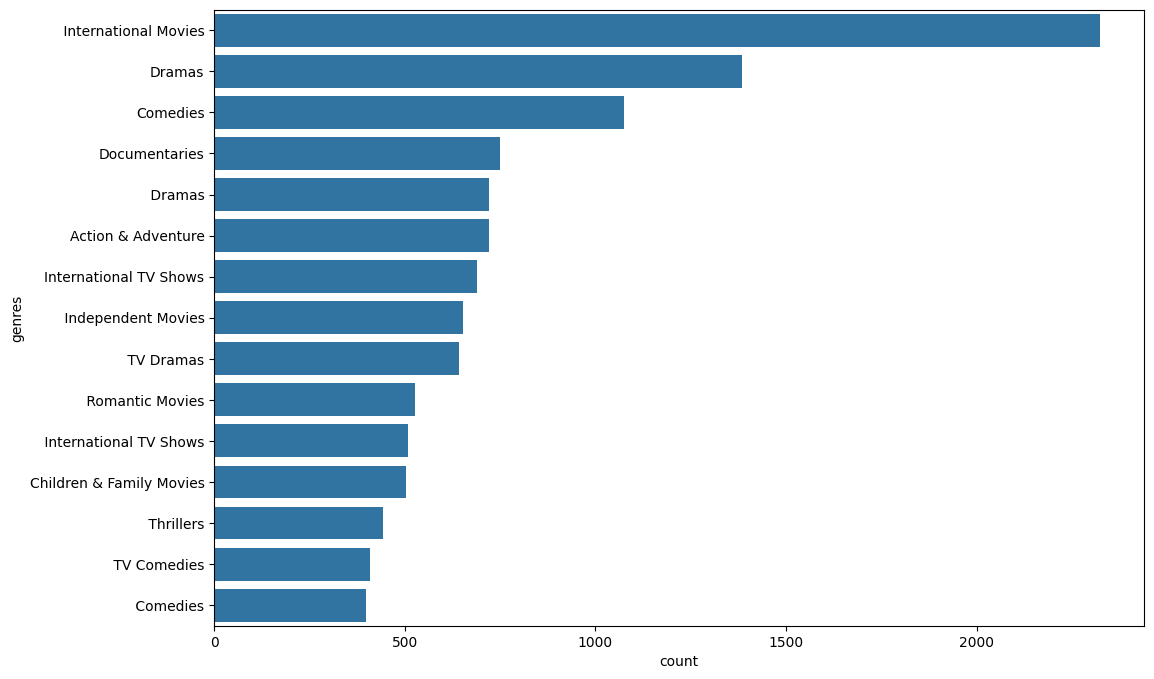

In [ ]:
#Visualization of top 15 genres on Netflix
plt.figure(figsize=(12,8))
sns.countplot(y=gen_df['genres'], data=gen_df, order=gen_df['genres'].value_counts().index[:15])

As we can see in the above count plot, international movies, dramas, comedies and action and adventureare some of the top genres.

**Cast**

In [ ]:
#Extracting top crew members from cast
crew_list=[]
for i in df['cast']:
  i=i.split(',')
  for j in i:
    crew_list.append(j)

In [ ]:
#Converting the list into dataframe
crew_df=pd.DataFrame(crew_list)
crew_df.rename(columns= {0:'actr_actrs'}, inplace=True)
crew_df

,actr_actrs
0,João Miguel
1,Bianca Comparato
2,Michel Gomes
3,Rodolfo Valente
4,Vaneza Oliveira
...,...
56599,Chittaranjan Tripathy
56600,Nasty C
56601,Adriano Zumbo
56602,Rachel Khoo


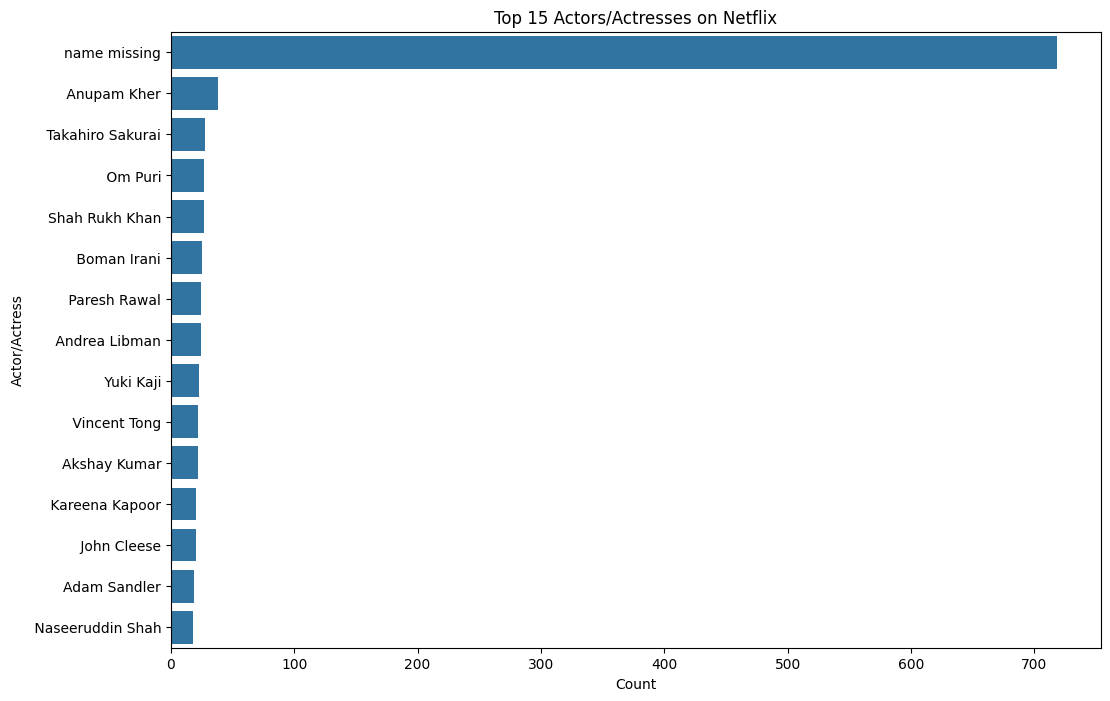

In [ ]:
#top 15 actor or actresses on netflix
plt.figure(figsize=(12,8))
sns.countplot(
    y=crew_df['actr_actrs'],
    data= crew_df,
    order= crew_df['actr_actrs'].value_counts().index[:15]
)
plt.title("Top 15 Actors/Actresses on Netflix")
plt.xlabel("Count")
plt.ylabel("Actor/Actress")
plt.show()

Anupam Kher, Takahiro Sakurai, Shah Rukh Khan, Boman Irani, etc are some of the top actors on Netflix. I had also some null values present in the cast column. It would have been easier to get more insights if some of the values in the cast column were ot null.

## **Movies Duration**

In [ ]:
#seperating the movies data from type column
movie_df = df[df['type']=='Movie'].copy()

#Extract only the duration value (before 'min or any test)
movie_df['duration']=movie_df['duration'].apply(lambda x: x.split("  ")[0])

#Reset index after processing
movie_df = movie_df.reset_index(drop=True)

movie_df


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,added_day,added_month,added_year
0,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,2016-12-23,2016,Adults,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...,23,12,2016
1,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,2018-12-20,2011,Adults,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow...",20,12,2018
2,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,2017-11-16,2009,Teens,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi...",16,11,2017
3,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,2020-01-01,2008,Teens,123 min,Dramas,A brilliant group of students become card-coun...,1,1,2020
4,s7,Movie,122,Yasir Al Yasiri,"Amina Khalil, Ahmed Dawood, Tarek Lotfy, Ahmed...",Egypt,2020-06-01,2019,Adults,95 min,"Horror Movies, International Movies","After an awful accident, a couple admitted to ...",1,6,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5372,s7782,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,2020-01-11,2006,Older Kids,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero...",11,1,2020
5373,s7783,Movie,Zozo,Josef Fares,"Imad Creidi, Antoinette Turk, Elias Gergi, Car...","Sweden, Czech Republic, United Kingdom, Denmar...",2020-10-19,2005,Adults,99 min,"Dramas, International Movies",When Lebanon's Civil War deprives Zozo of his ...,19,10,2020
5374,s7784,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,2019-03-02,2015,Teens,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...,2,3,2019
5375,s7785,Movie,Zulu Man in Japan,name absent,Nasty C,United States,2020-09-25,2019,Adults,44 min,"Documentaries, International Movies, Music & M...","In this documentary, South African rapper Nast...",25,9,2020


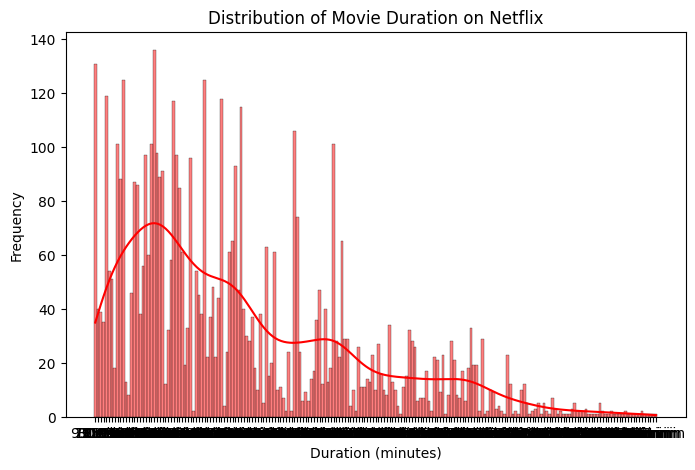

In [ ]:
#visualization of movies duration distribution
plt.figure(figsize=(8,5))
sns.histplot(movie_df['duration'], color= 'red', kde =True, bins=20)
plt.title("Distribution of Movie Duration on Netflix")
plt.xlabel("Duration (minutes)")
plt.ylabel("Frequency")
plt.show()

The range duration of the movies on Netflix is between 50 to 150 minutes. There are also are also some movies of 300 minutes.

# **TV Shows Duration**

In [ ]:
#tv shows df
tv_df = df[df['type']=='TV Shows']
tv_df['duration'].value_counts()
df.loc[df['type']=='TV Shows']['duration'].value_counts()

,count
duration,


<Axes: >

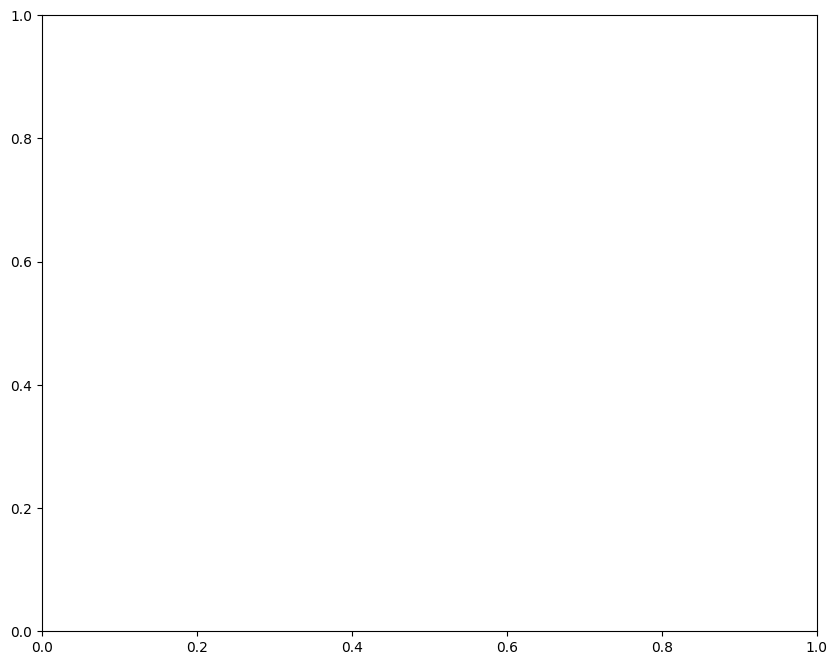

In [ ]:
#Visualization of TV show duration
plt.figure(figsize=(10,8))
sns.countplot(y=tv_df['duration'])


**counts wrt type of the content**

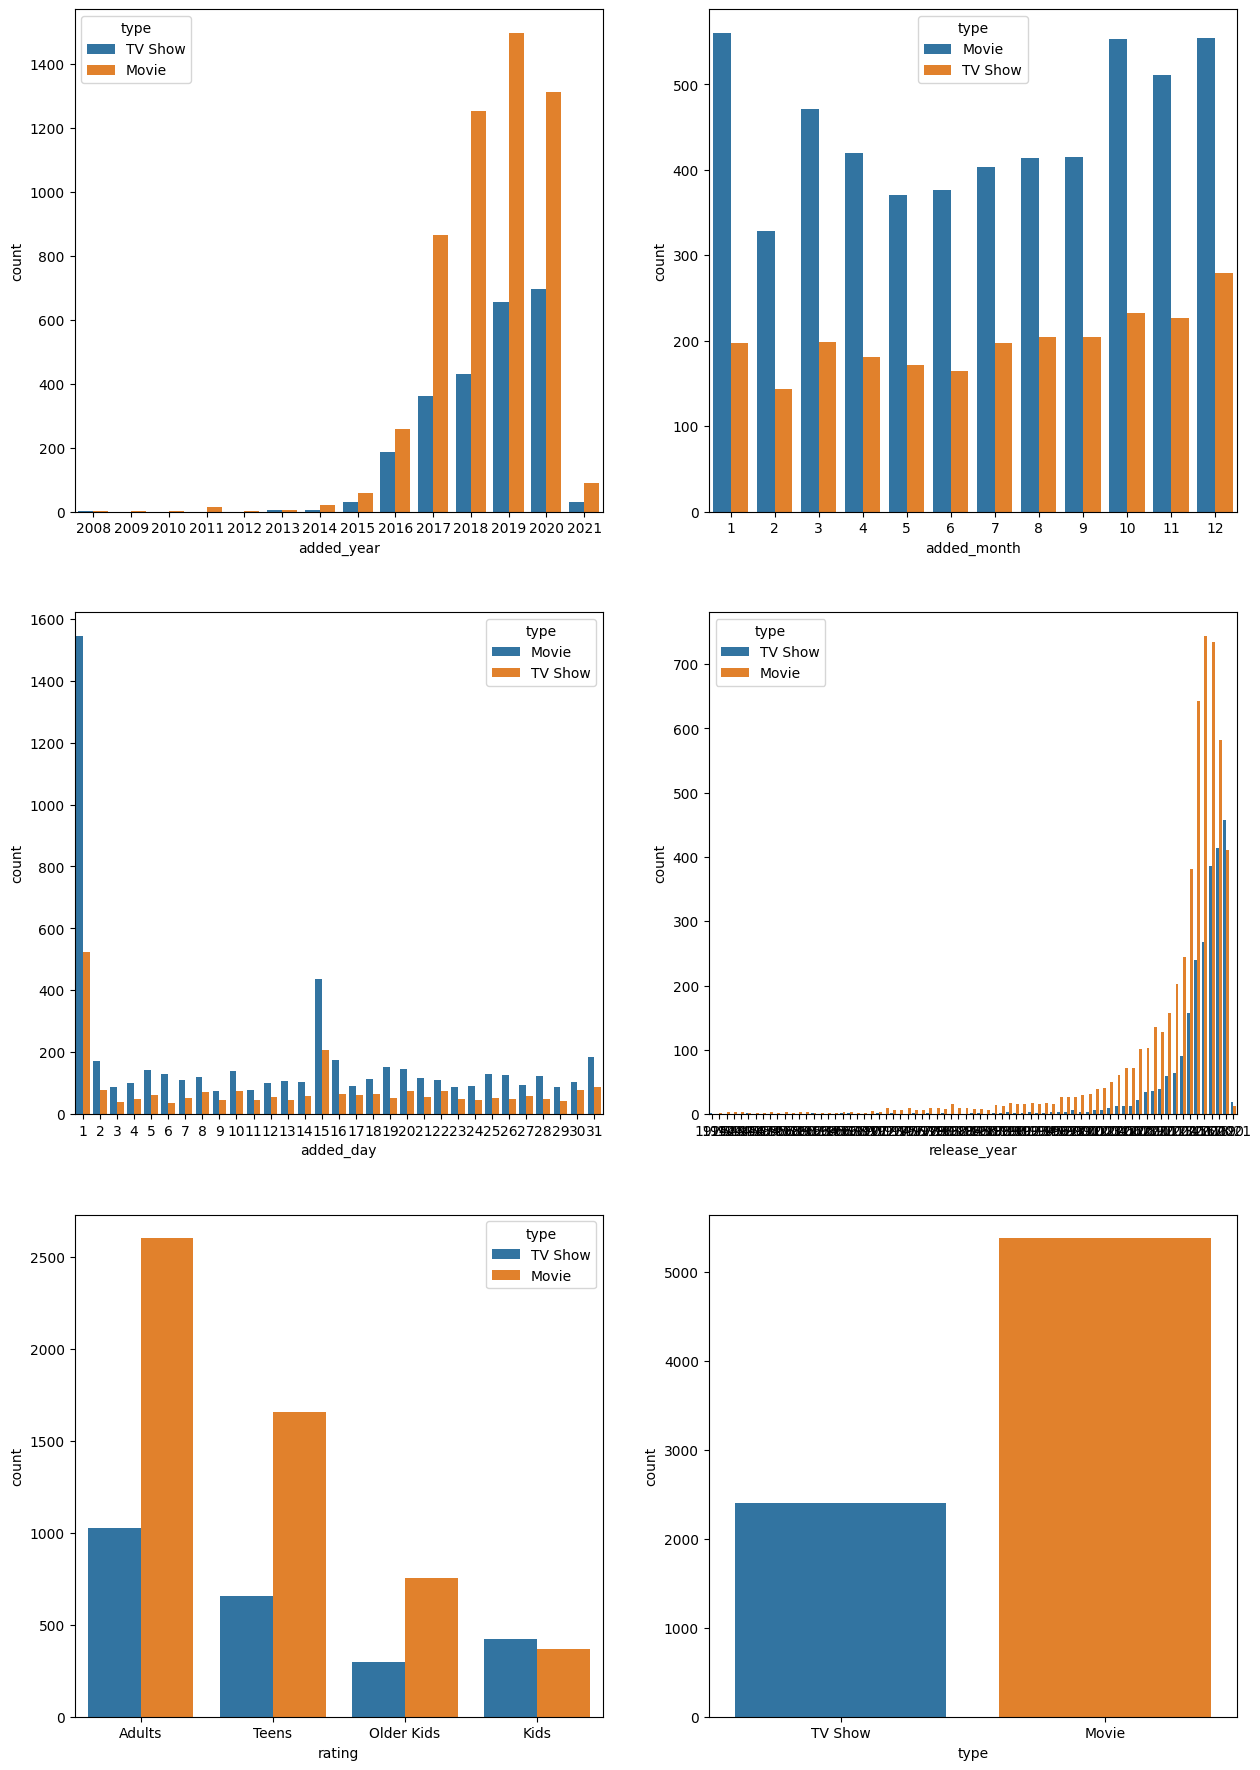

In [ ]:
#counts wrt type of the content
plt.figure(figsize=(15,30))
for i in enumerate(var):
  plt.subplot(4,2, i[0]+1)
  sns.countplot(x= i[1], hue = 'type', data = df)

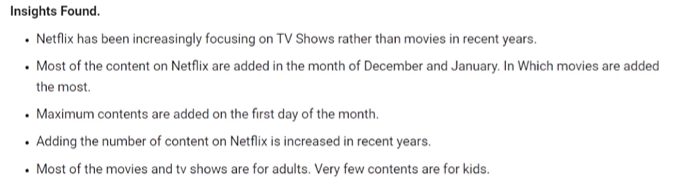

# **Type content available in different countries**

<Axes: xlabel='country', ylabel='count'>

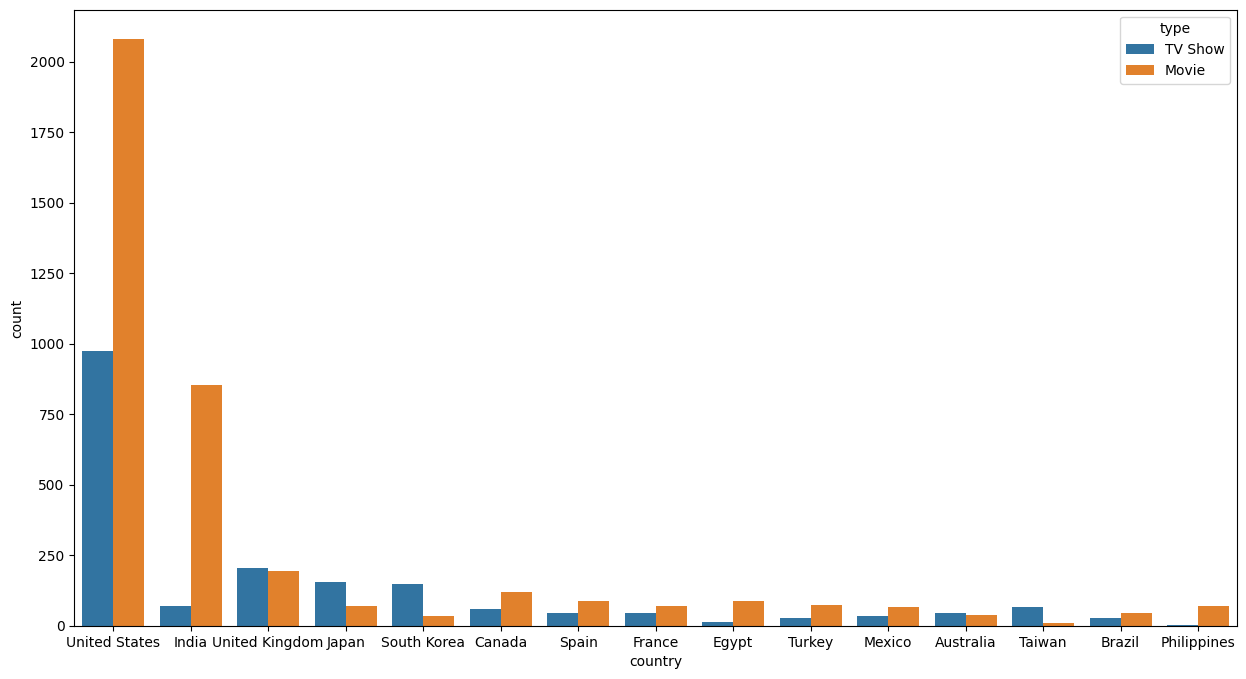

In [ ]:
#Total production of country wrt type of the content
plt.figure(figsize=(15,8))
sns.countplot(x=df['country'], hue='type', data=df, order=df['country'].value_counts().index[:15])

# US has the most number of movies and tv shows type content. While India comes in second place for movies on Netflix. But UK comes in second place in terms of tv shows. Followed by South Korea and Canada. Other countries have a very less number of contents added on Netflix.

# **Feature Engineering**

# There are no outliers in the data so I don't have to handle any outliers here. While I cleaned the data completely in the data wrangling section. Like handled the null values, converted the ratings into an understandable format, and extracted the date data from date_added column.

# **Textual Data Processing**

In [ ]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [ ]:
#Combining the textual data to proceed with NLP
df['text'] = df ['cast']+df ['rating']+ df['description']+df['rating']+df['country']
df['text'][0]

'João Miguel, Bianca Comparato, Michel Gomes, Rodolfo Valente, Vaneza Oliveira, Rafael Lozano, Viviane Porto, Mel Fronckowiak, Sergio Mamberti, Zezé Motta, Celso FrateschiAdultsIn a future where the elite inhabit an island paradise far from the crowded slums, you get one chance to join the 3% saved from squalor.AdultsBrazil'

In [ ]:
def remove_punctuation(text):
    '''a function for removing punctuation'''
    import string
    # replacing the punctuations with no space,
    # which in effect deletes the punctuation marks
    translator = str.maketrans('', '', string.punctuation)
    # return the text stripped of punctuation marks
    return text.translate(translator)

In [ ]:
import string

# Function to remove punctuation safely
def remove_punctuation(text):
    # Convert all values to string first to avoid float/NaN errors
    text = str(text)
    translator = str.maketrans('', '', string.punctuation)
    return text.translate(translator)

# Applying the function
df['text'] = df['text'].apply(remove_punctuation)

# Displaying the first cleaned text
print(df['text'][0])


João Miguel Bianca Comparato Michel Gomes Rodolfo Valente Vaneza Oliveira Rafael Lozano Viviane Porto Mel Fronckowiak Sergio Mamberti Zezé Motta Celso FrateschiAdultsIn a future where the elite inhabit an island paradise far from the crowded slums you get one chance to join the 3 saved from squalorAdultsBrazil


# **Removing stopwords**

In [ ]:
 #downloading stopwords
 import nltk
 nltk.download('stopwords')
 from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
#assigning the stopwords to a variable
stop_words = stopwords.words('english')

#displaying stopwords
np.array(stop_words)

array(['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all',
       'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at',
       'be', 'because', 'been', 'before', 'being', 'below', 'between',
       'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did',
       'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don',
       "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further',
       'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven',
       "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers',
       'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd",
       'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it',
       "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll',
       'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn',
       "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not',
       'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'ot

In [ ]:
#function to remove stopwords from a given text
def remove_stopwords(text):
  '''a function for removing the stopword'''
  #removing the stop words and lowercasing the selected words
  text=[word.lower() for word in text.split() if word.lower() not in stop_words]
  #joining the list of words with space seperator
  return " ".join(text)

In [ ]:
# 1. Define stop words
stop_words = set([
    'a', 'an', 'the', 'and', 'or', 'is', 'in', 'it', 'of', 'to', 'for', 'on', 'with', 'as', 'by', 'at'
])

# 2. Define the function
def remove_stopwords(text):
    '''Function for removing stopwords'''
    # Make sure text is string
    text = str(text)
    # Remove stop words and lowercase
    words = [word.lower() for word in text.split() if word.lower() not in stop_words]
    return " ".join(words)

# 3. Apply the function on your dataframe
df['text'] = df['text'].apply(remove_stopwords)

# 4. Print first row
print(df['text'][0])


joão miguel bianca comparato michel gomes rodolfo valente vaneza oliveira rafael lozano viviane porto mel fronckowiak sergio mamberti zezé motta celso frateschiadultsin future where elite inhabit island paradise far from crowded slums you get one chance join 3 saved from squaloradultsbrazil


# **Stemming Operations**

# Text Normalization

In [ ]:
#function for stemming and lemmatization
stemmer= SnowballStemmer("english")

def stemming(text):
  '''a function which stems each word in the given text'''
  text=[stemmer.stem(word) for word in text.split()]
  return " ".join(text)

In [ ]:
#applying function on text data
from nltk.stem import PorterStemmer
import pandas as pd

ps = PorterStemmer()

def stemming(text):
    return " ".join([ps.stem(word) for word in text.split()])

print(df.columns)

if 'description' in df.columns:
    df['text'] = df['description'].fillna('')
elif 'title' in df.columns:
    df['text'] = df['title'].fillna('')
else:
    raise KeyError("No suitable text column found. Expected 'description' or 'title'.")

df['text'] = df['text'].apply(stemming)

print(df['text'].head())


Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description',
       'text'],
      dtype='object')
0    in a futur where the elit inhabit an island pa...
1    after a devast earthquak hit mexico city, trap...
2    when an armi recruit is found dead, hi fellow ...
3    in a postapocalypt world, rag-dol robot hide i...
4    a brilliant group of student becom card-count ...
Name: text, dtype: object


In [ ]:
#tfidf object initialization
tfidf = TfidfVectorizer(stop_words='english', lowercase=False, max_features=10000) #max features = 10000 to prevent system from crashing

#fitting the vectorizer using the text data
tfidf.fit(df['text'])

#collecting the vocabulary items used in the vectorizer
dictionary = tfidf.vocabulary_.items()

In [ ]:
#converting vector into array form for clustering
X= tfidf.transform(df['text']).toarray()

#summarize encoded vector
print(X)
print(f'shape of the vector: { X.shape}')
print(f'datatype : {type(X)}')

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.23359811 0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]
shape of the vector: (7787, 10000)
datatype : <class 'numpy.ndarray'>


# **Applying PCA to reduce dimension**

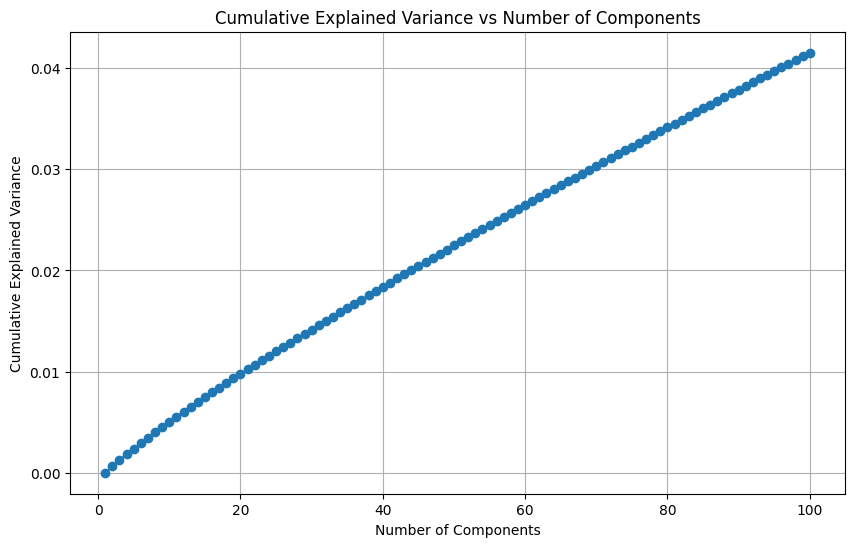

In [ ]:
# Importing libraries
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler

# Scaling the data
scaler = StandardScaler(with_mean=False)
X_scaled = scaler.fit_transform(X)

# Applying TruncatedSVD for dimensionality reduction
pca = TruncatedSVD(n_components=100, random_state=42)
X_reduced = pca.fit_transform(X_scaled)

# Calculating explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()

# Plotting cumulative explained variance
plt.figure(figsize=(10,6))
plt.plot(range(1, len(explained_variance)+1), cumulative_variance, marker='o', linestyle='--')
plt.title('Cumulative Explained Variance vs Number of Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.show()


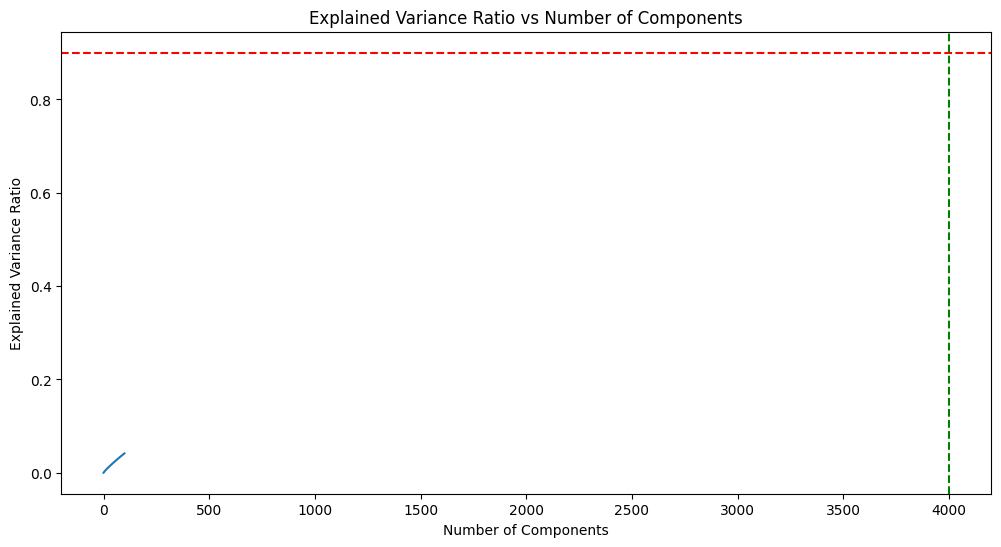

In [ ]:
#Calculate the explained variance ratio for each component
explained_variance_ratio = pca.explained_variance_ratio_

#Plot the explained variance ratio
plt.figure(figsize=(12,6))
plt.plot(np.cumsum(explained_variance_ratio))
plt.xlabel('Number of Components')
plt.ylabel('Explained Variance Ratio')
plt.title('Explained Variance Ratio vs Number of Components')
plt.axhline(y=0.9, color='red', linestyle='--')
plt.axvline(x=4000, color='green', linestyle='--')
plt.show()


As I can see clearly in the above graph that the data with 4000 components cover 90 percen variation. If we have approximately 7000 components then it will capture 100% variance but that will increase the model complexity. So with this information, I'm going to reduce the dimension.

In [ ]:
X.shape

(7787, 10000)

In [ ]:
# Assuming your dataframe is named df
# and already loaded earlier in your notebook

from sklearn.decomposition import IncrementalPCA

# Select only numeric columns for PCA
X = df.select_dtypes(include=['float64', 'int64'])

# Ensure component count doesn’t exceed number of features
n_components = min(4000, X.shape[1])

# Apply Incremental PCA (faster & memory efficient)
ipca = IncrementalPCA(n_components=n_components, batch_size=256)
transformed_data = ipca.fit_transform(X)

print(transformed_data.shape)




(7787, 1)


In [ ]:
#copy of the transformed data
net_data = transformed_data.copy()

# **ML Model**

# **K-Means Clustering**

**Elbow Method**

In [ ]:
#finding the k value through elbow method
k_value = range(2,12)
ssd_value= []
for k in k_value:
  kmeans= KMeans(n_clusters=k, init = 'k-means++', random_state = 42)
  kmeans.fit(net_data)
  ssd_value.append(kmeans.inertia_)

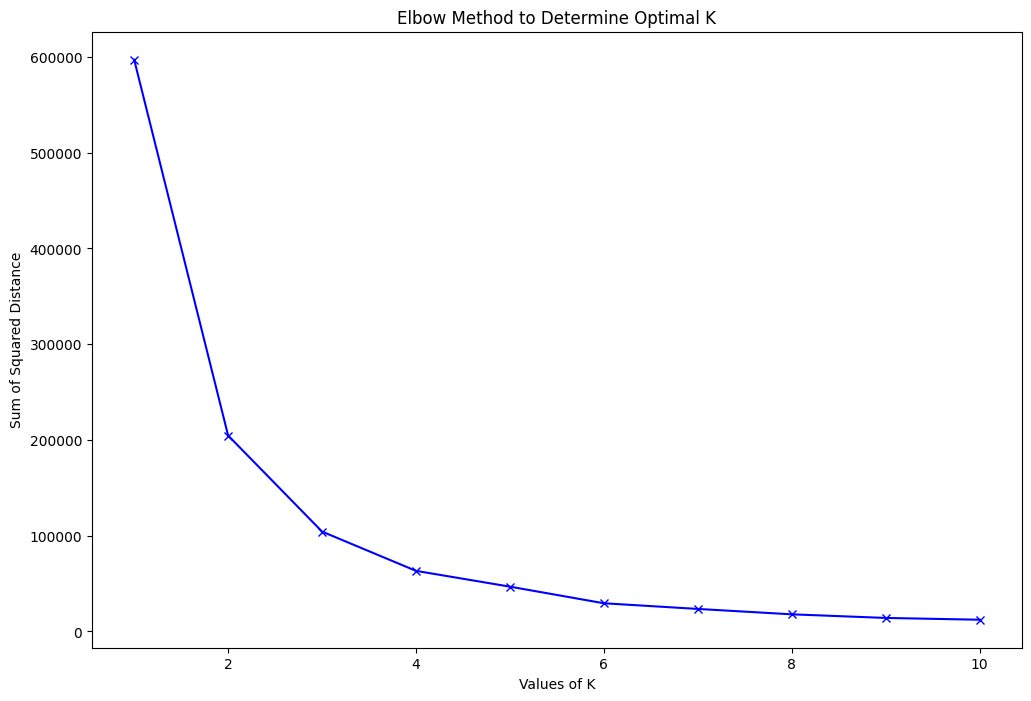

In [ ]:
from sklearn.cluster import KMeans

# Make sure your feature data (X) is already defined and numeric
# Example: X = df.select_dtypes(include=['float64', 'int64'])

# Define K range
k_value = range(1, 11)
ssd_value = []  # Sum of Squared Distances

# Calculate SSD for each K
for k in k_value:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    ssd_value.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(12,8))
plt.plot(k_value, ssd_value, 'bx-')
plt.xlabel('Values of K')
plt.ylabel('Sum of Squared Distance')
plt.title('Elbow Method to Determine Optimal K')
plt.show()


Here I can see a sudden stipness after 6 clusters. After 6 cluster value, the within-cluster sum of squares(WSS) starts to decrease at a slower rate. So according to elbow curve the optimal value for k is 6. Let's see the silhoutte score.

Silhoutte Score

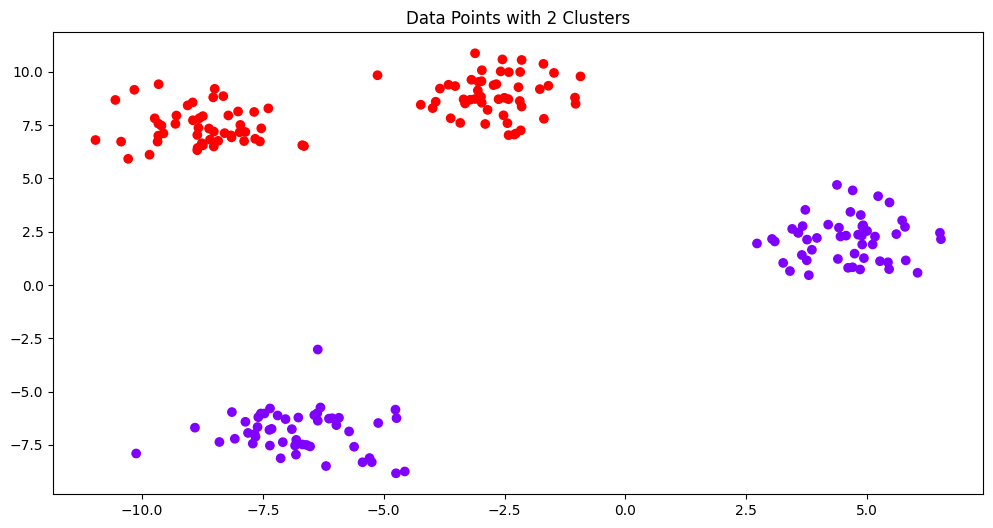

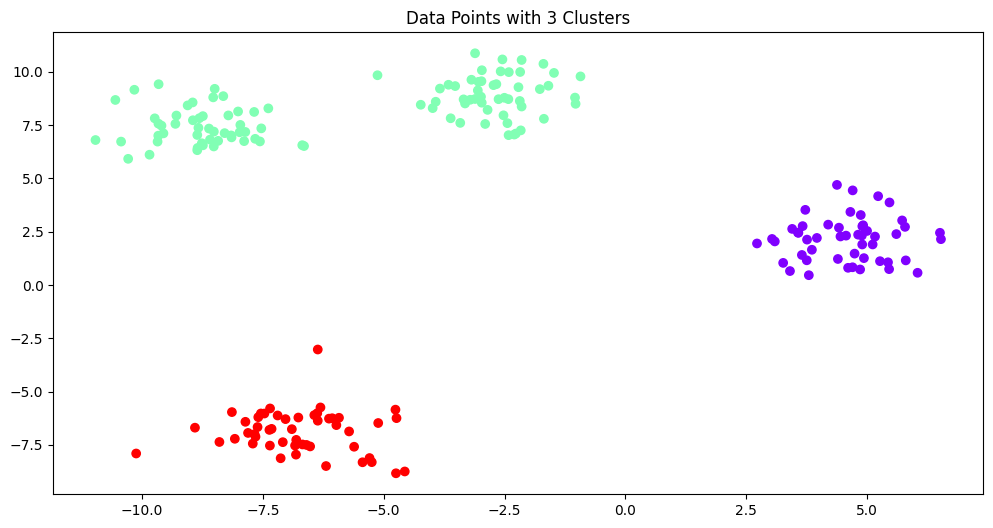

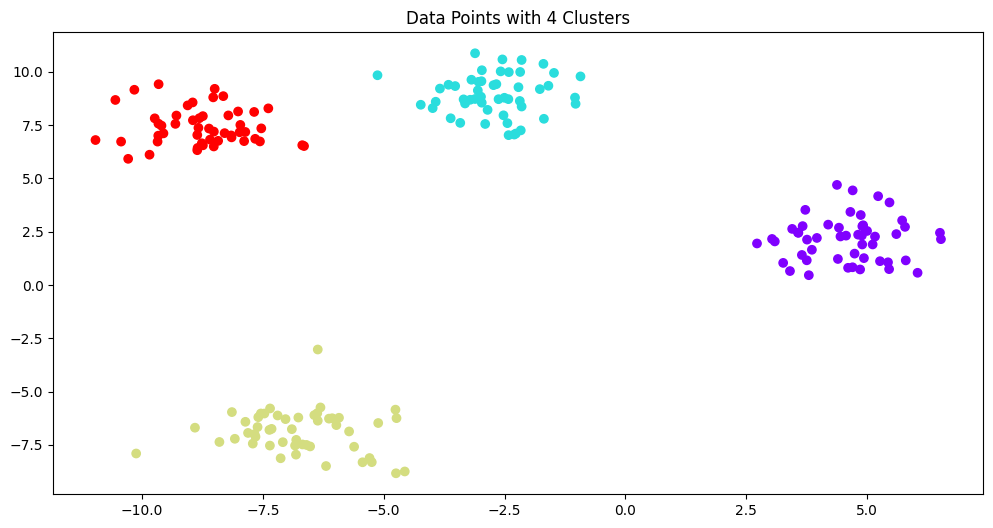

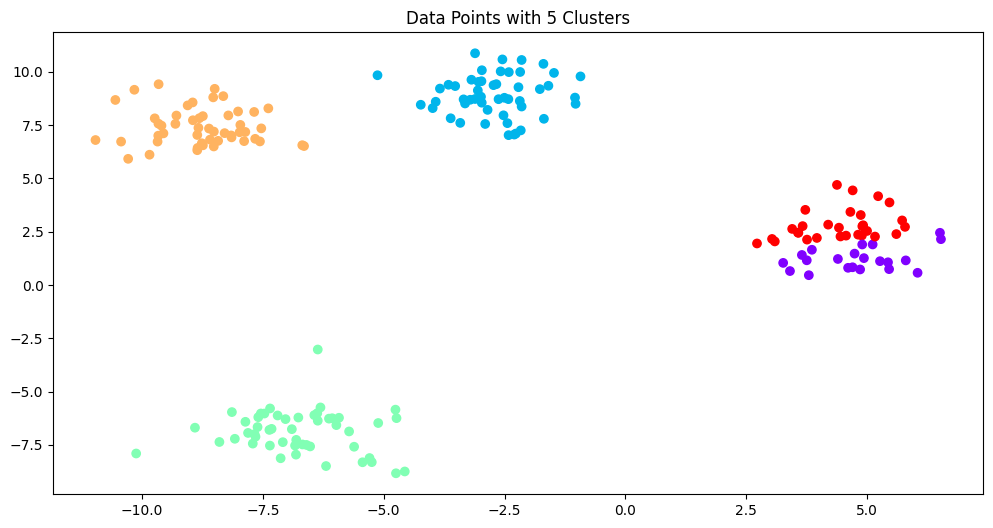

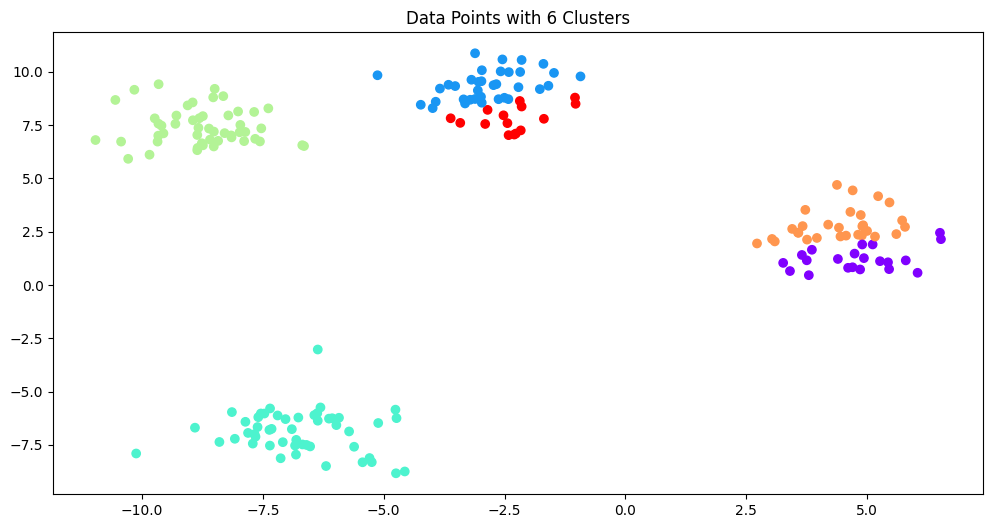

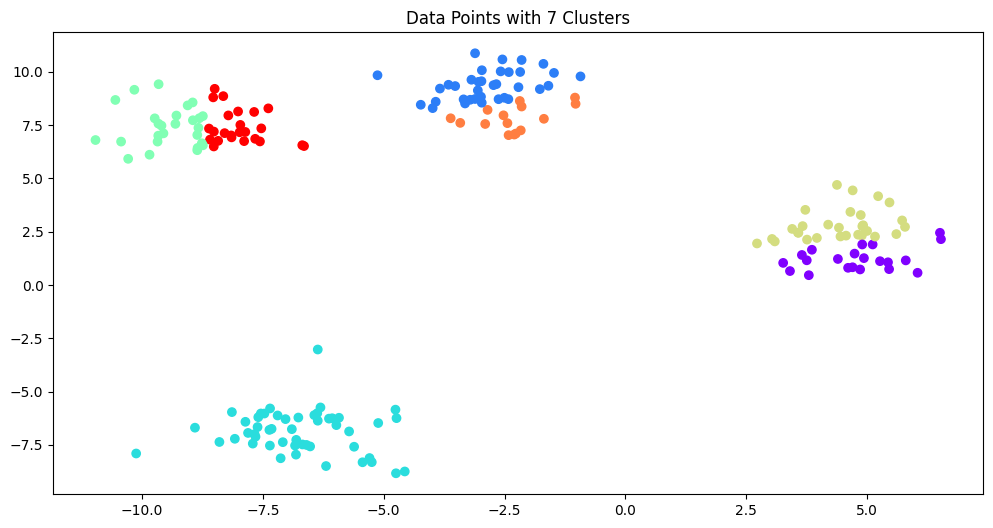

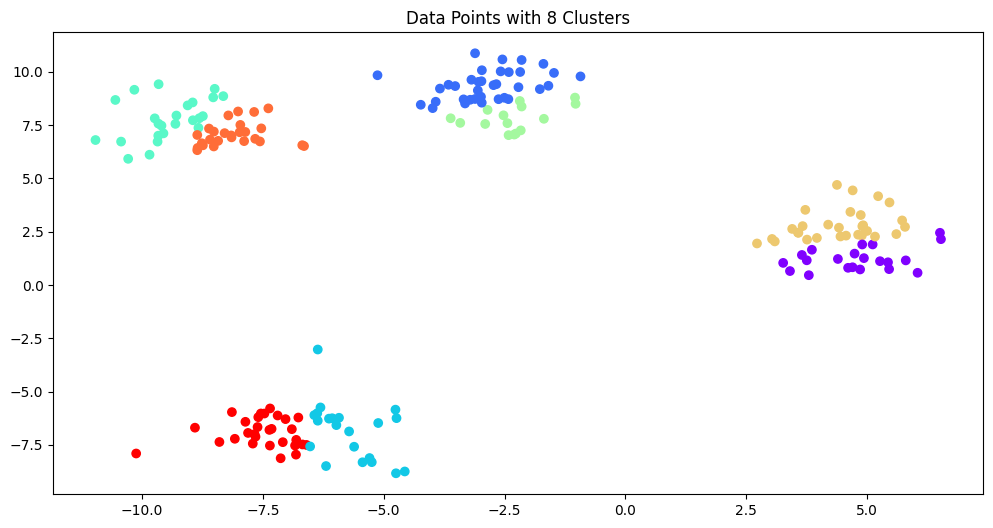

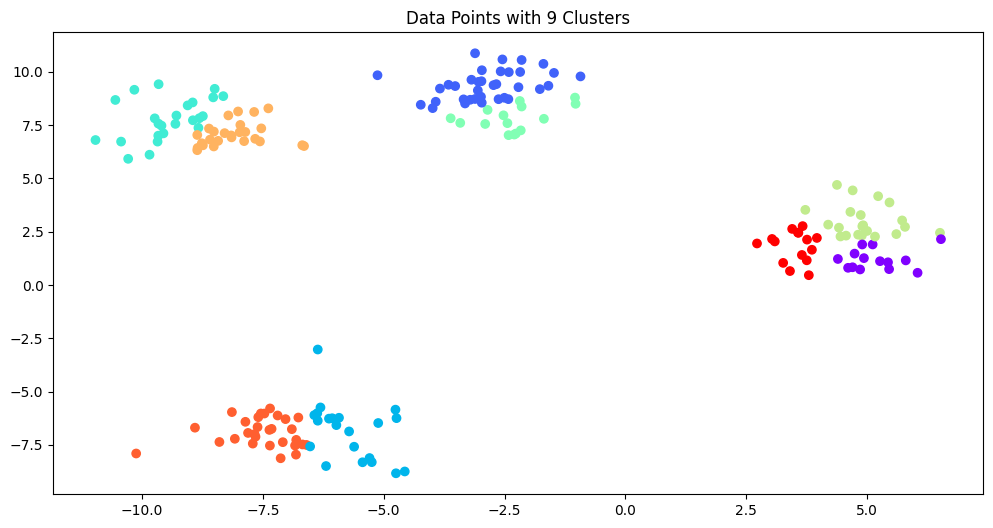

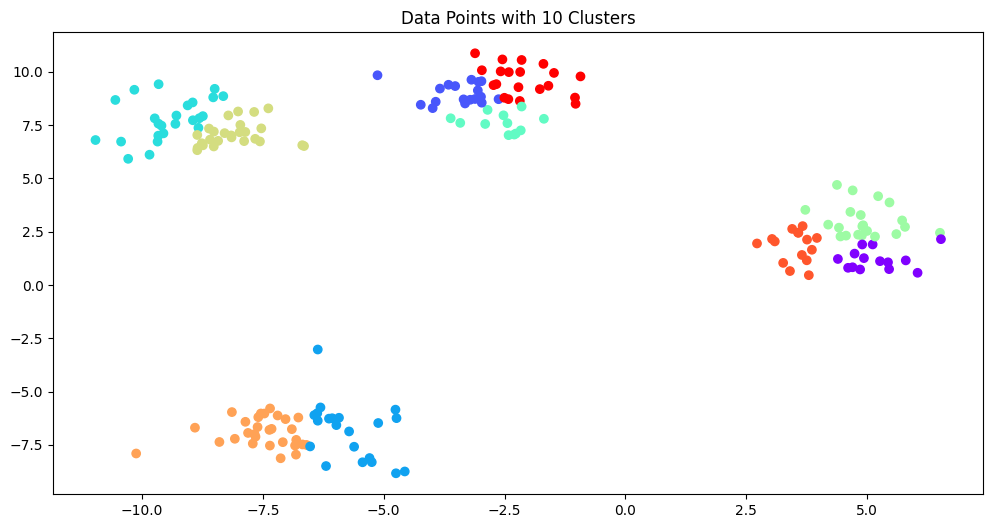

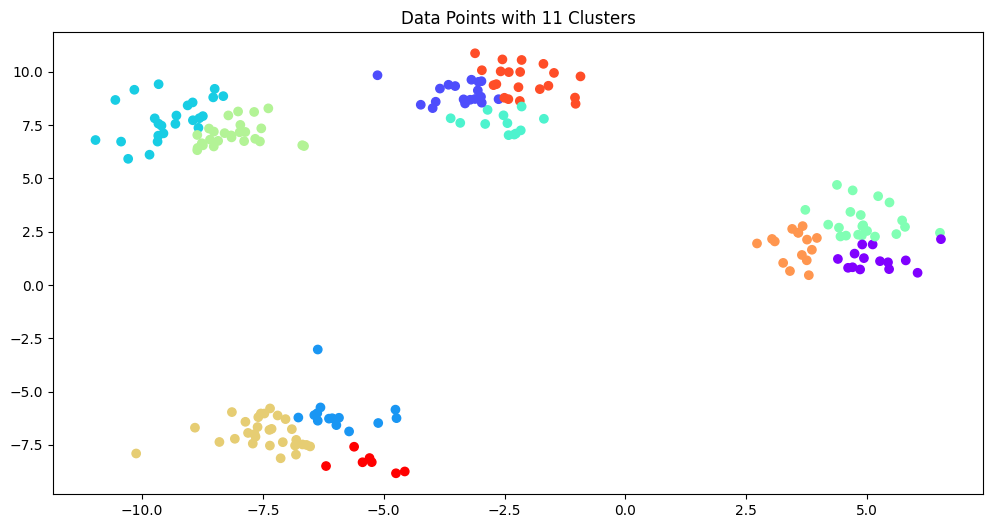

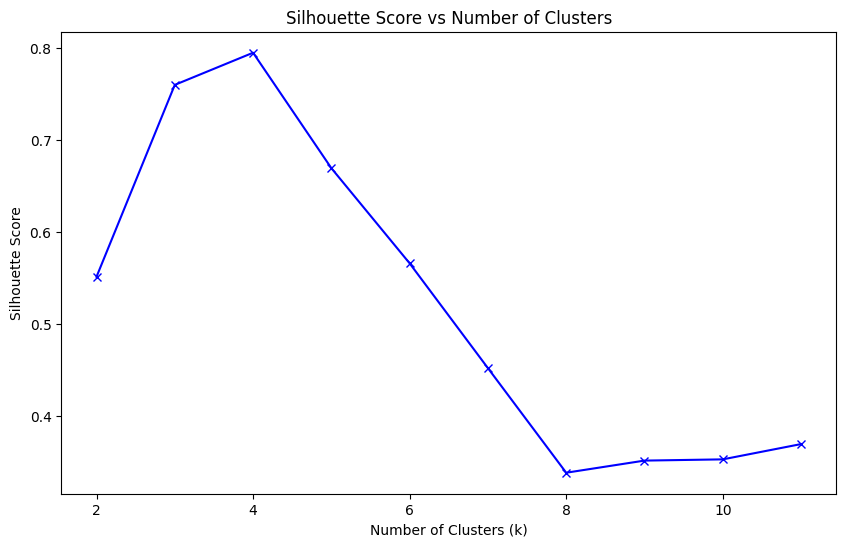

In [ ]:
from sklearn.datasets import make_blobs

net_data, _ = make_blobs(n_samples=200, n_features=2, centers=4, random_state=42)

n_cluster_range = range(2, 12)
silhouette_avg_score = []
cluster_label_list = []

for k in n_cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    cluster_labels = kmeans.fit_predict(net_data)
    cluster_label_list.append(cluster_labels)
    silhouette_avg = silhouette_score(net_data, cluster_labels)
    silhouette_avg_score.append(silhouette_avg)

    plt.figure(figsize=(12,6))
    plt.scatter(net_data[:, 0], net_data[:, 1], c=cluster_labels, cmap='rainbow')
    plt.title(f'Data Points with {k} Clusters')
    plt.show()

plt.figure(figsize=(10,6))
plt.plot(list(n_cluster_range), silhouette_avg_score, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs Number of Clusters')
plt.show()





As we can see here the data points with 6 clusters are good enough. It would be more clear with sillhouette score visualization.

Visualization of silhouette score with different value of k

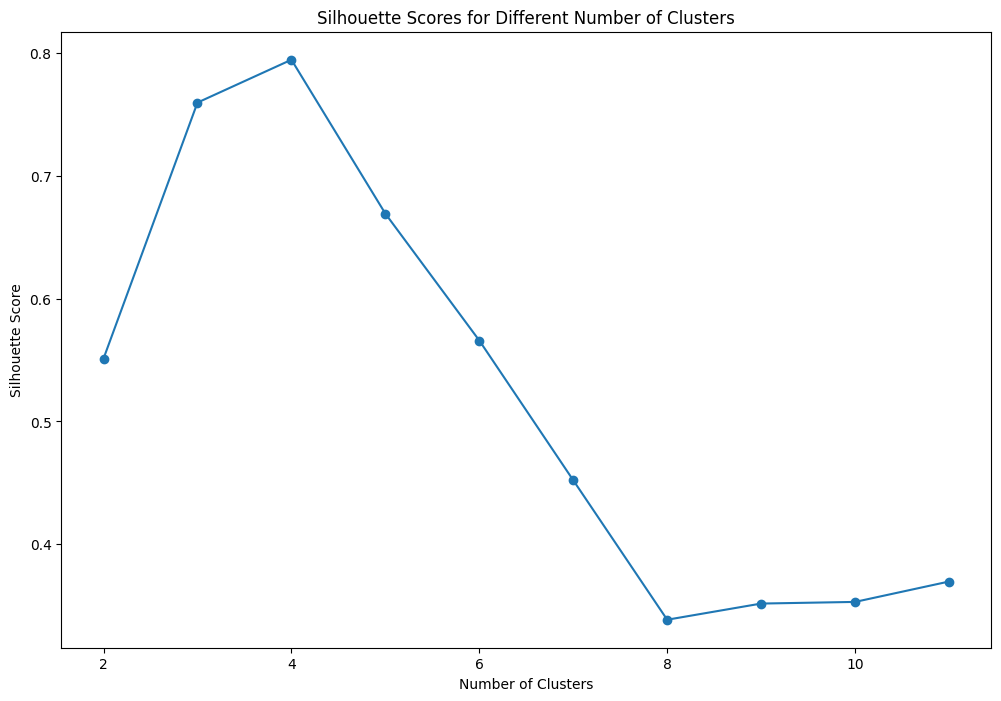

In [ ]:
# Plotting the silhouette scores as a function of number of clusters
plt.figure(figsize=(12,8))
plt.plot(n_cluster_range, silhouette_avg_score, marker='o')

# Add labels to the plot
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores for Different Number of Clusters')

# Show the plot
plt.show()


According to the above line plot, with 6 clusters we get a good score. Which is really good as compared to different number of clusters.

**Final K Means model**

In [ ]:
# final model.
kmeans = KMeans(n_clusters=6, max_iter=10000, tol=1e-4, n_init=1, random_state=42)
kmeans.fit(net_data)

KMeans(max_iter=10000, n_clusters=6, n_init=1, random_state=42)

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Fit KMeans on reduced data
kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(X_reduced)

# Predict cluster labels
labels = kmeans.labels_

# Evaluate model using silhouette score
score = silhouette_score(X_reduced, labels)
print("Silhouette score is:", score)



Silhouette score is: 0.06998781979730495


In [ ]:
# creating a new column as cluster with cluster number5s.
df['cluster'] = kmeans.labels_

In [ ]:
# first five rows.
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,text,cluster
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...,in a futur where the elit inhabit an island pa...,3
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...,"after a devast earthquak hit mexico city, trap...",0
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow...","when an armi recruit is found dead, hi fellow ...",3
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi...","in a postapocalypt world, rag-dol robot hide i...",3
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...,a brilliant group of student becom card-count ...,0


In [ ]:
# value count of different clusters.
df['cluster'].value_counts()


,count
cluster,
0,4413
2,1535
3,1414
4,424
1,1


<Axes: xlabel='cluster', ylabel='count'>

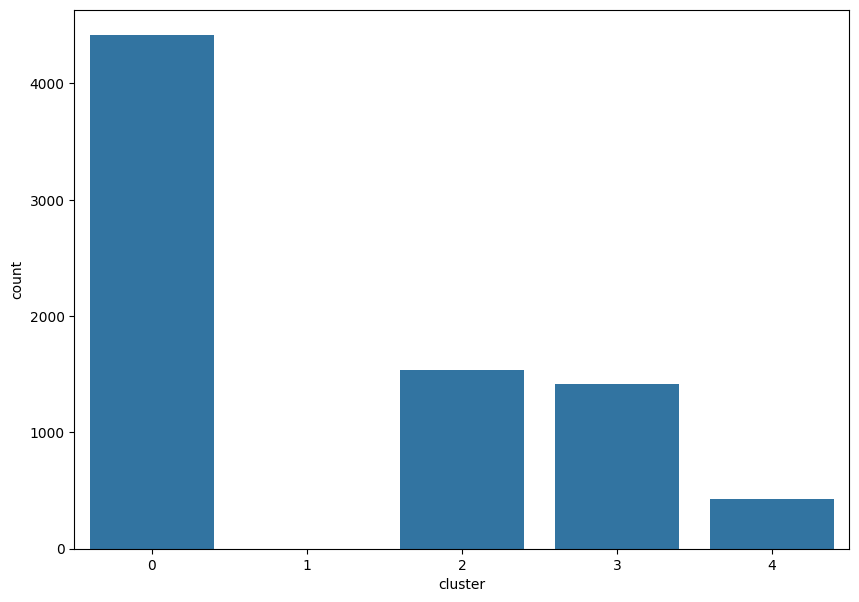

In [ ]:
# Size of clusters formed
plt.figure(figsize=(10,7))
sns.countplot(x =df['cluster'], data = df)


## Cluster 5 and 0 has got the maximum number of data points while cluster 1 and 3 has got less than 1000 data points. Cluster 2 has approximately 1200 data points.

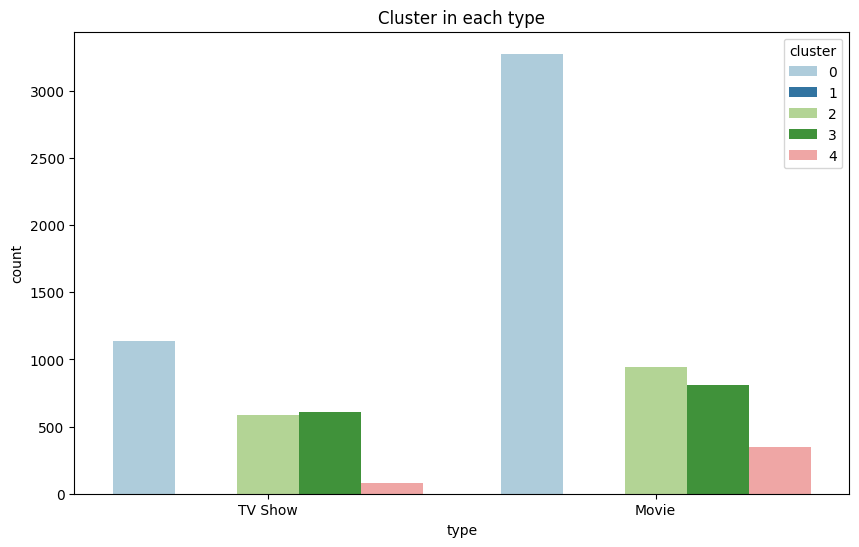

In [ ]:
# Plotting clusters for each type
plt.figure(figsize=(10,6))
sns.countplot(data=df, x="type", hue="cluster", palette="Paired")
plt.title("Cluster in each type")
plt.show()



Maximum content in all the cluster labels are movies.

**Dendogram**

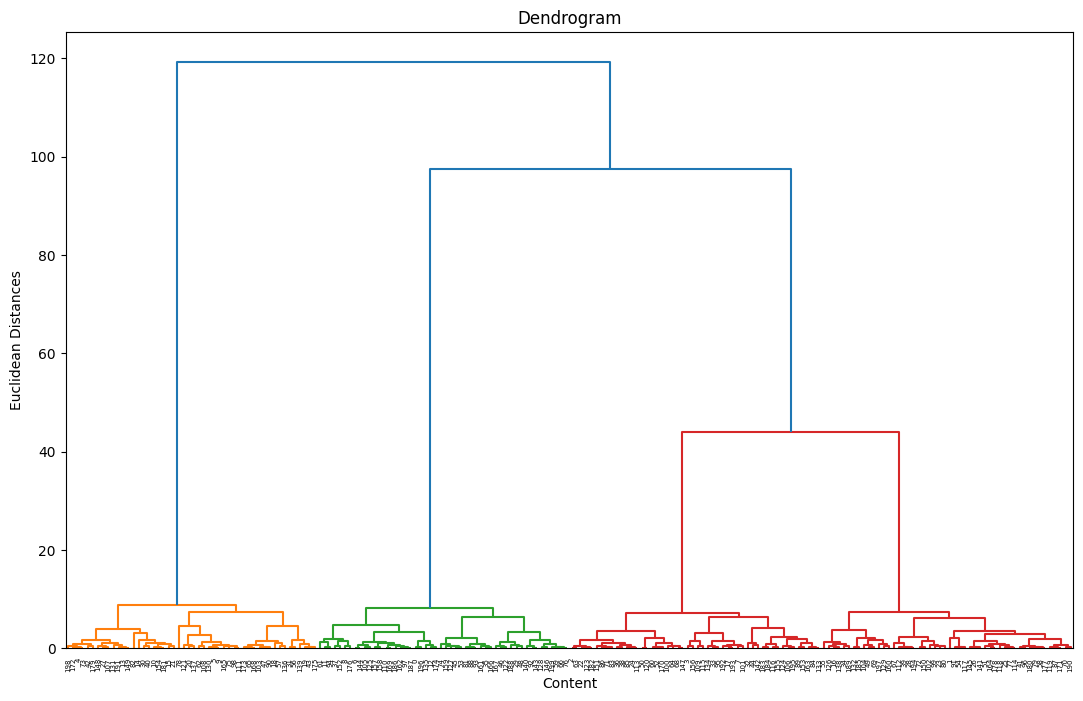

In [ ]:
# Using the dendrogram to find the optimal number of clusters
import scipy.cluster.hierarchy as sch
plt.figure(figsize=(13, 8))
dendrogram = sch.dendrogram(sch.linkage(net_data, method = 'ward'))
plt.title('Dendrogram')
plt.xlabel('Content')
plt.ylabel('Euclidean Distances')
plt.show()


As per the dendrogram, if we cut the tallest vertical line which shows the distance between those clusters, we'll get 4 clusters with 5 Euclidean distance.

# **Hierarchial Clustering**

**Agglomerative Clustering**

In [ ]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X_reduced)


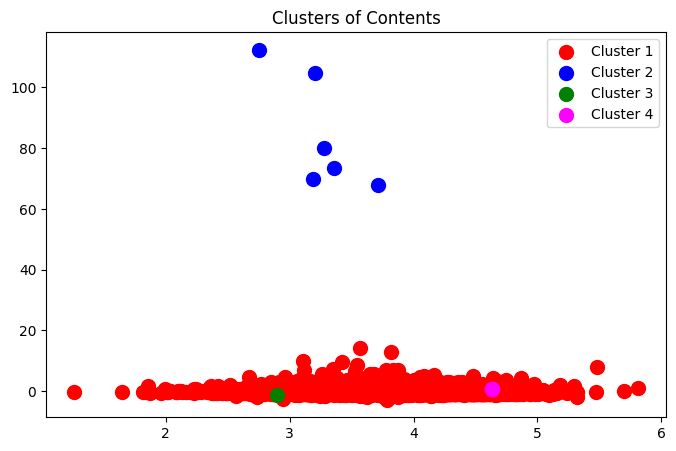

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(X_reduced[y_hc == 0, 0], X_reduced[y_hc == 0, 1], s=100, c='red', label='Cluster 1')
plt.scatter(X_reduced[y_hc == 1, 0], X_reduced[y_hc == 1, 1], s=100, c='blue', label='Cluster 2')
plt.scatter(X_reduced[y_hc == 2, 0], X_reduced[y_hc == 2, 1], s=100, c='green', label='Cluster 3')
plt.scatter(X_reduced[y_hc == 3, 0], X_reduced[y_hc == 3, 1], s=100, c='magenta', label='Cluster 4')

plt.title('Clusters of Contents')
plt.legend()
plt.show()


In [ ]:
#count of each cluster
np.unique(y_hc, return_counts=True)

(array([0, 1, 2, 3]), array([7777,    6,    1,    3]))

Nearly 6000 data points belong to cluster label 0, 992 belongs to 1. 847 belongs to label 3 and only 192 belongs to cluster label 2.

# **Conclusion**

Netflix's library is primarily made up of movies, but in recent years, there's been a noticeable shift toward producing more TV shows. Most of the content targets adult audiences, with relatively few titles aimed at teens and children. Interestingly, the bulk of new releases tend to appear in December and January. When looking at specific days, the first day of the month sees the highest number of additions, followed by the first day of the third week.

Since many features in the dataset were textual, I used natural language processing (NLP) techniques to clean and prepare the data. This preprocessing expanded the feature space to 10,000 dimensions, so I applied Principal Component Analysis (PCA) to reduce it down to 4,000.

For clustering, I experimented with both KMeans and Agglomerative Clustering. Using the elbow method and silhouette scores, KMeans initially suggested 5 clusters, but I ultimately selected 6 as the optimal number. Later, a dendrogram analysis indicated that 4 clusters would be more appropriate, so I finalized the model using Agglomerative Clustering with four clusters.